# Stage 2 — Optimization Dynamics on the Leak-Detection Data (revised)

Demonstrates, on the Phase 1 pipeline-leak data, three results from *Understanding Deep Learning* (Prince):
1. **Ch. 8** — bias–variance trade-off and (model-wise) double descent,
2. **Ch. 7** — vanishing / exploding gradients (forward *and* backward propagation; effect of initialisation, depth, optimizer),
3. **Ch. 9.2** — implicit regularisation: gradient descent / SGD versus continuous-time gradient flow (modified loss).

**Before running:** execute the generator-side export cell (`export_scenario_ids_phase1.py`) once in the Phase 1 notebook. It writes `pooled_*.npy` into the Phase 2 folder.
**Run order:** top to bottom. Set `SMOKE_TEST = True` in cell 1 first to verify the whole notebook in minutes.

Main changes vs. the previous version: scenario-level splits (no row leakage) · K disjoint training sets and a real bias²/variance decomposition · width sweep at fixed depth up to the interpolation regime ·
targets rescaled so the μ-head actually trains · constant-predictor baseline + task metrics · forward and backward statistics instead of weight-matrix norms · element-wise gradient clipping removed ·
ODE code fixed and the comparison made mathematically valid (GD/SGD vs. flow, not Adam vs. flow).

**Dataset limitation:** The reconstructed dataset contains 373 leak scenarios
(1–3 leaks per scenario). Zero-leak scenarios were excluded because their
scenario grouping could not be reliably validated. Consequently, all
experiments evaluate leak localization and related optimization behaviour
conditional on leak scenarios being present. They do not establish
general leak-versus-no-leak detection performance.

In [17]:
# ============================== 1. SETUP & CONFIGURATION ==============================
import os, time, json, math, copy, pickle, random, warnings
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from matplotlib import pyplot as plt
from torchdiffeq import odeint

plt.style.use('dark_background')
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

DATA_DIR = r"C:\Data\pipeline-leakage-system\Phase 2"     # pooled_*.npy written by the generator-side export cell
OUT_DIR  = DATA_DIR                                          # results / figures / checkpoints
os.makedirs(OUT_DIR, exist_ok=True)

SEED = 0
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_everything(SEED)

# Set True first: runs every part of the notebook on a tiny configuration (minutes) to verify your setup.
SMOKE_TEST = False

CFG = dict(
    # ---- data / splitting ----
    test_frac   = 0.20,     # fraction of SCENARIOS held out as the fixed test set
    K_sets      = 8,        # number of DISJOINT scenario-level training sets (bias-variance needs several)
    # ---- Part 3: capacity sweep (one hidden layer, width sweep) ----
    widths      = [1, 2, 4, 8, 16, 32, 64, 96, 128, 192, 256, 384, 512, 768, 1024, 1536, 2048],
    epochs      = 600,
    batch_size  = 64,
    lr          = 1e-3,
    lr_schedule = "cosine", # 'const' or 'cosine' (decays to cosine_min_frac*lr); lets large models settle toward interpolation
    cosine_min_frac = 0.01,
    max_retries = 2,        # a run that diverges / stays above retry_factor x constant-baseline loss is retried with lr/3
    retry_factor = 3.0,
    # noise knobs (applied ONLY inside this notebook; Phase 1 data are untouched)
    #   sensor_std : Gaussian noise (in standardized-feature units) added to train inputs (one fixed draw per training set) and to the test inputs
    #   label_frac : fraction of TRAIN rows whose label vector is replaced by the label vector of a random other train row
    noise_configs = [dict(name="clean",        sensor_std=0.0, label_frac=0.0),
                     dict(name="label_noise",  sensor_std=0.0, label_frac=0.20),
                     dict(name="sensor_noise", sensor_std=0.5, label_frac=0.0)],
    # ---- Part 4: forward / backward propagation ----
    p4_width    = 64,
    p4_depths   = [2, 5, 10, 20, 30, 50],
    p4_var_mults= [0.25, 0.5, 1.0, 2.0, 4.0],      # sigma_w^2 = c * 2/fan_in  (c = 1 is He init)
    p4_show_depth = 30,
    p4_repeats  = 3,                                # init seeds x minibatches averaged (geometric mean)
    p4b_depth   = 20,
    p4b_steps   = 400,
    p4b_var_mults = [0.5, 1.0, 2.0],
    p4b_sgd_lrs  = [1e-2, 1e-1, 1.0, 10.0, 100.0],
    p4b_adam_lrs = [1e-4, 3e-4, 1e-3, 3e-3],
    p4b_seeds   = 3,
    # ---- Part 5: implicit regularization ----
    p5_leak_rows  = 128,
    p5_leak_width = 16,
    p5_n_alpha    = 5,        # alpha_k = alpha_0 / 2^k, k = 0..n_alpha-1
)

if SMOKE_TEST:
    CFG.update(K_sets=2, widths=[2, 8, 32], epochs=15, max_retries=0,
               noise_configs=[dict(name="clean", sensor_std=0.0, label_frac=0.0),
                              dict(name="label_noise", sensor_std=0.0, label_frac=0.20)],
               p4_depths=[2, 5, 10], p4_var_mults=[0.5, 1.0, 2.0], p4_show_depth=10, p4_repeats=1,
               p4b_depth=5, p4b_steps=40, p4b_sgd_lrs=[1.0, 10.0], p4b_adam_lrs=[1e-3, 3e-3], p4b_seeds=1,
               p5_leak_rows=32, p5_leak_width=4, p5_n_alpha=3)
    OUT_DIR = os.path.join(OUT_DIR, "smoke_test"); os.makedirs(OUT_DIR, exist_ok=True)
    print(">>> SMOKE TEST MODE: tiny configuration, results are NOT meaningful <<<")


Using device: cuda


## 2. Data — pooled load, scenario-level split, preprocessing

In [18]:
# ============================== 2. DATA: POOLED LOAD, SCENARIO-LEVEL SPLIT, PREPROCESSING ==============================
# Why: the Phase 1 CSVs were split ROW-wise, so every test leak row had an exact twin (same scenario, other hour) in train
# (diagnostic: 1837/1837). Here we pool everything and split by SCENARIO, so train and test share no scenario.
STD_EPS = 1e-6      # input columns with std below this are treated as constant (std := 1), as the original did for std == 0

def _need(name):
    p = os.path.join(DATA_DIR, name)
    if not os.path.exists(p):
        raise FileNotFoundError(f"{p} not found - run the generator-side export cell in the Phase 1 notebook first.")
    return p

X_raw   = np.load(_need("pooled_X.npy"))
Y_raw   = np.load(_need("pooled_Y.npy"))
sid_raw = np.load(_need("pooled_scenario_ids.npy"))
with open(_need("pooled_columns.json")) as f: meta = json.load(f)
ZERO_POLICY_USED = meta.get("zero_leak_policy", "n/a (ids supplied by the generator)")
print("zero-leak policy used at export:", ZERO_POLICY_USED)
if ZERO_POLICY_USED == "drop":
    print("NOTE: zero-leak rows were dropped at export (their scenario grouping could not be validated). All metrics below refer to leak scenarios only; the model never sees a no-leak row.")
n_rows, d_in = X_raw.shape
d_y = Y_raw.shape[1]
assert Y_raw.shape[0] == n_rows == len(sid_raw), "pooled arrays have inconsistent row counts"

# ---------- group structure + strict verification of the scenario ids ----------
order = np.argsort(sid_raw, kind="stable")
uniq, starts, counts = np.unique(sid_raw[order], return_index=True, return_counts=True)
rows_by_scen = dict(zip(uniq.tolist(), np.split(order, starts[1:])))
Y_sorted = Y_raw[order]
same_y = np.array_equal(np.minimum.reduceat(Y_sorted, starts, axis=0),
                        np.maximum.reduceat(Y_sorted, starts, axis=0), equal_nan=True)
assert same_y, "leak_C differs between rows that share a scenario id -> scenario ids are misaligned with the rows."
if "time_of_day" in meta["input_columns"]:
    t = X_raw[:, meta["input_columns"].index("time_of_day")]
    n_unique_t = pd.Series(t).groupby(sid_raw).nunique().reindex(uniq).to_numpy()
    assert (n_unique_t == counts).all(), "duplicate time_of_day inside a scenario -> scenario ids look wrong."
n_leaks_scen = (Y_sorted[starts] > 0).sum(1)                       # leaks per scenario (aligned with `uniq`)
leak_keys = {Y_sorted[s].tobytes() for s, k in zip(starts, n_leaks_scen) if k > 0}
if len(leak_keys) != int((n_leaks_scen > 0).sum()):
    warnings.warn("two leak scenarios share an identical leak vector (unexpected for continuous leak_C).")
print(f"rows={n_rows}  inputs={d_in}  targets={d_y}  scenarios={len(uniq)}  "
      f"rows/scenario min/median/max = {counts.min()}/{int(np.median(counts))}/{counts.max()}")
print("scenarios by #leaks:", dict(zip(*np.unique(n_leaks_scen, return_counts=True))))
if n_rows != 9562 + 2390:
    print(f"note: pooled rows ({n_rows}) != 9562 + 2390 of the old CSV split")

# ---------- scenario-level split: fixed test set + K disjoint training sets (stratified by #leaks) ----------
rng = np.random.default_rng(SEED)
test_scen, pool_by_k = [], {}
for k in np.unique(n_leaks_scen):
    ids = rng.permutation(uniq[n_leaks_scen == k])
    n_te = int(round(CFG["test_frac"] * len(ids)))
    test_scen += ids[:n_te].tolist(); pool_by_k[int(k)] = ids[n_te:]
ranked = sorted(((r, k, s) for k, ids in pool_by_k.items() for r, s in enumerate(ids)), key=lambda z: (z[0], z[1]))
pool_order = np.array([s for _, _, s in ranked])                   # interleaves the strata, so contiguous chunks are balanced
K_SETS = CFG["K_sets"]; S_PER_SET = len(pool_order) // K_SETS
assert S_PER_SET >= 4, "too few pool scenarios for this many disjoint training sets; lower CFG['K_sets']"
sets_scen = [pool_order[i * S_PER_SET:(i + 1) * S_PER_SET] for i in range(K_SETS)]
rows_of   = lambda scen: np.concatenate([rows_by_scen[int(s)] for s in scen])
test_rows = rows_of(test_scen); pool_rows = rows_of(pool_order); set_rows = [rows_of(s) for s in sets_scen]
assert not (set(test_scen) & set(pool_order.tolist())) and len(set(np.concatenate(sets_scen).tolist())) == K_SETS * S_PER_SET
print(f"test: {len(test_scen)} scenarios / {len(test_rows)} rows | pool: {len(pool_order)} scenarios / {len(pool_rows)} rows | "
      f"{K_SETS} disjoint training sets of {S_PER_SET} scenarios (~{int(np.mean([len(r) for r in set_rows]))} rows each)")

# ---------- preprocessing (statistics from the training POOL only; test never used) ----------
X_f  = np.where(np.isnan(X_raw), 0.0, X_raw)                      # same as the original fillna(0)
mu_x = X_f[pool_rows].mean(0)
sd_x = X_f[pool_rows].std(0, ddof=1)                               # ddof=1 matches pandas .std() used originally
n_const = int((sd_x < STD_EPS).sum()); sd_x[sd_x < STD_EPS] = 1.0
X_all = torch.tensor(((X_f - mu_x) / sd_x).astype(np.float32), device=device)

# Target scaling: leak_C ~ 1e-5..6e-4, so (y - mu)^2 ~ 1e-8 and the regression head would never be trained under beta = 1.
# Dividing by a constant (median positive leak_C of the pool) puts positive targets at O(1). Set Y_SCALE = 1.0 to reproduce the old units.
pool_pos = Y_raw[pool_rows][Y_raw[pool_rows] > 0]
Y_SCALE  = float(np.median(pool_pos))
Y_all    = torch.tensor(Y_raw / Y_SCALE, dtype=torch.float32, device=device)

DATA = dict(x=X_all, y=Y_all, test_rows=test_rows, set_rows=set_rows, pool_rows=pool_rows, y_scale=Y_SCALE, d_in=d_in, d_y=d_y)
pos_scen_idx = np.searchsorted(uniq, pool_order)
events_per_junction = (Y_sorted[starts][pos_scen_idx] > 0).sum(0)
print(f"Y_SCALE (median positive leak_C) = {Y_SCALE:.3e} | near-constant input columns set to std=1: {n_const} | "
      f"max |z| over all rows = {X_all.abs().max().item():.1f}")
print(f"prior leak prob per output = {(Y_raw[pool_rows] > 0).mean():.2e} | leak events per junction in the pool: "
      f"median {np.median(events_per_junction[events_per_junction > 0]):.0f}, junctions never leaking: {(events_per_junction == 0).sum()}/{d_y}")

# ---------- noise knobs (training sets / test set are built here; originals stay clean in DATA) ----------
def make_training_set(k, noise_cfg):
    rows = torch.as_tensor(DATA["set_rows"][k], device=device)
    x, y = DATA["x"][rows].clone(), DATA["y"][rows].clone()
    n = len(rows); g = torch.Generator(device="cpu"); g.manual_seed(10_000 * (k + 1) + SEED)
    if noise_cfg["label_frac"] > 0:                      # replace a fraction of label vectors by those of random train rows
        flip  = (torch.rand(n, generator=g) < noise_cfg["label_frac"]).to(device)
        donor = torch.randint(0, n, (n,), generator=g).to(device)
        y_new = y.clone(); y_new[flip] = y[donor][flip]; y = y_new
    if noise_cfg["sensor_std"] > 0:
        x = x + noise_cfg["sensor_std"] * torch.randn(x.shape, generator=g).to(device)
    return x, y

def make_test_set(noise_cfg):                            # test LABELS always clean; sensor noise (if any) is one fixed draw
    rows = torch.as_tensor(DATA["test_rows"], device=device)
    x, y = DATA["x"][rows].clone(), DATA["y"][rows].clone()
    if noise_cfg["sensor_std"] > 0:
        g = torch.Generator(device="cpu"); g.manual_seed(777 + SEED)
        x = x + noise_cfg["sensor_std"] * torch.randn(x.shape, generator=g).to(device)
    return x, y


zero-leak policy used at export: drop
NOTE: zero-leak rows were dropped at export (their scenario grouping could not be validated). All metrics below refer to leak scenarios only; the model never sees a no-leak row.
rows=8952  inputs=3755  targets=1242  scenarios=373  rows/scenario min/median/max = 24/24/24
scenarios by #leaks: {np.int64(1): np.int64(124), np.int64(2): np.int64(125), np.int64(3): np.int64(124)}
note: pooled rows (8952) != 9562 + 2390 of the old CSV split
test: 75 scenarios / 1800 rows | pool: 298 scenarios / 7152 rows | 8 disjoint training sets of 37 scenarios (~888 rows each)
Y_SCALE (median positive leak_C) = 7.934e-05 | near-constant input columns set to std=1: 143 | max |z| over all rows = 1104.2
prior leak prob per output = 1.61e-03 | leak events per junction in the pool: median 1, junctions never leaking: 753/1242


## 3. Core definitions — model, init, loss, from-scratch SGD/Adam, training loop

In [19]:
# ============================== 3. CORE DEFINITIONS: model, init, loss, optimizers, training ==============================
def DNN(D_i, D_k, D_o, dtype=torch.float32):
    """Fully-connected ReLU network D_i -> D_k[0] -> ... -> D_o (no activation after the last layer)."""
    sizes = [D_i] + list(D_k) + [D_o]
    layers = []
    for i in range(len(sizes) - 1):
        layers.append(nn.Linear(sizes[i], sizes[i + 1]))
        if i < len(sizes) - 2: layers.append(nn.ReLU())
    return nn.Sequential(*layers).to(device=device, dtype=dtype)

def init_params(model, var_mult=1.0, prior_logit_bias=None, mu_bias=None):
    """Weights ~ N(0, var_mult * 2/fan_in)  (var_mult = 1.0 is exactly He / kaiming_normal_ for ReLU), biases = 0.
    Optional output-bias initialisation (used for the leak network, NOT for the Part 4 init study):
    logit biases := prior log-odds of each output, mu bias := mean positive target -> the network starts AT the constant predictor."""
    lin = [m for m in model if isinstance(m, nn.Linear)]
    with torch.no_grad():
        for m in lin:
            nn.init.normal_(m.weight, 0.0, math.sqrt(var_mult * 2.0 / m.in_features))
            nn.init.zeros_(m.bias)
        if prior_logit_bias is not None:
            D = lin[-1].out_features // 2
            lin[-1].bias[:D] = prior_logit_bias.to(lin[-1].bias.dtype)
            lin[-1].bias[D:] = float(mu_bias)

def split_outputs(out):
    D = out.shape[1] // 2
    return out[:, :D], out[:, D:]          # (logits, mu)

def leak_loss_from_output(out, y, alpha=1.0, beta=1.0):
    """Homoscedastic loss of Phase 1: alpha*BCE(leak indicator) + beta*mean( p * (y - mu)^2 ); y in scaled units."""
    logits, mu = split_outputs(out)
    c = (y > 0).to(out.dtype)
    cls = F.binary_cross_entropy_with_logits(logits, c)               # mean over batch x outputs
    reg = torch.mean(torch.sigmoid(logits) * (y - mu) ** 2)
    return alpha * cls + beta * reg

# ---------------- optimizers written from scratch (per-parameter tensors, no flatten/copy) ----------------
class SGDScratch:
    def __init__(self, params, lr, momentum=0.0):
        self.params, self.lr, self.mom = list(params), lr, momentum
        self.buf = [torch.zeros_like(p) for p in self.params] if momentum > 0 else None
    @torch.no_grad()
    def step(self, grads, lr=None):
        lr = self.lr if lr is None else lr
        for i, (p, g) in enumerate(zip(self.params, grads)):
            if self.buf is not None:
                self.buf[i].mul_(self.mom).add_(g); g = self.buf[i]
            p.sub_(lr * g)

class AdamScratch:
    """m <- b1 m + (1-b1) g ;  v <- b2 v + (1-b2) g^2 ;  p <- p - lr * m_hat / (sqrt(v_hat) + eps)   (bias-corrected).
    grad_clip=None disables the element-wise clamp that the old notebook applied (it hid exploding gradients)."""
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, grad_clip=None):
        self.params, self.lr, self.b1, self.b2, self.eps, self.clip = list(params), lr, betas[0], betas[1], eps, grad_clip
        self.m = [torch.zeros_like(p) for p in self.params]; self.v = [torch.zeros_like(p) for p in self.params]; self.t = 0
    @torch.no_grad()
    def step(self, grads, lr=None):
        lr = self.lr if lr is None else lr
        self.t += 1
        c1, c2 = 1 - self.b1 ** self.t, 1 - self.b2 ** self.t
        for p, g, m, v in zip(self.params, grads, self.m, self.v):
            if self.clip is not None: g = g.clamp(-self.clip, self.clip)
            m.mul_(self.b1).add_(g, alpha=1 - self.b1)
            v.mul_(self.b2).addcmul_(g, g, value=1 - self.b2)
            p.sub_(lr * (m / c1) / ((v / c2).sqrt() + self.eps))

def make_optimizer(name, params, lr, **kw):
    return AdamScratch(params, lr, **kw) if name == "adam" else SGDScratch(params, lr, **kw)

# ---------------- generic minibatch training loop ----------------
def train_model(model, opt, x, y, epochs, batch_size, seed, lr_schedule="const", min_lr_frac=0.01,
                loss_from_output=leak_loss_from_output, loss_every=0):
    """Returns dict(diverged, steps, loss_curve). Finite-ness is checked once per epoch (no per-step GPU sync)."""
    N = x.shape[0]; params = list(model.parameters())
    g = torch.Generator(device=x.device); g.manual_seed(seed)
    steps_per_epoch = math.ceil(N / batch_size); total = epochs * steps_per_epoch; step = 0
    base_lr, curve, diverged = opt.lr, [], False
    for epoch in range(epochs):
        perm = torch.randperm(N, device=x.device, generator=g)
        for i in range(0, N, batch_size):
            idx = perm[i:i + batch_size]
            loss = loss_from_output(model(x[idx]), y[idx])
            grads = torch.autograd.grad(loss, params)
            lr_t = base_lr if lr_schedule == "const" else base_lr * (min_lr_frac + (1 - min_lr_frac) * 0.5 * (1 + math.cos(math.pi * step / total)))
            opt.step(grads, lr=lr_t); step += 1
        if not torch.isfinite(loss).item(): diverged = True; break
        if loss_every and (epoch + 1) % loss_every == 0: curve.append((epoch + 1, loss.item()))
    return dict(diverged=diverged, steps=step, loss_curve=curve)

@torch.no_grad()
def predict_outputs(model, x, chunk=1024):
    return torch.cat([model(x[i:i + chunk]) for i in range(0, x.shape[0], chunk)])

# ---------------- constant-predictor baseline (an input-independent model fitted on the same training set) ----------------
def fit_constant_baseline(y_train):
    c = (y_train > 0).float()
    prior = c.mean(0)                                                 # per-output leak frequency
    mean_int = y_train.mean(0)                                        # per-output mean intensity (unconditional)
    pos = y_train[y_train > 0]
    mu_pos = pos.mean() if pos.numel() else torch.tensor(1.0, device=y_train.device)
    return dict(prior=prior, mean_int=mean_int, mu_pos=mu_pos)

def baseline_output(base, n):
    pr = base["prior"].clamp(1e-6, 1 - 1e-6)
    logit = torch.log(pr / (1 - pr)).unsqueeze(0).expand(n, -1)
    mu = base["mu_pos"].expand(n, pr.numel())
    return torch.cat([logit, mu], dim=1)


## 4. Metrics and bias–variance machinery

In [20]:
# ============================== 4. METRICS AND BIAS-VARIANCE MACHINERY ==============================
@torch.no_grad()
def micro_average_precision(scores, labels):
    """Average precision over ALL (row, junction) pairs (micro-averaged PR curve). Ties are broken by a stable sort."""
    s, l = scores.flatten(), labels.flatten().double()
    n_pos = l.sum()
    if n_pos.item() == 0: return float("nan")
    l_sorted = l[torch.sort(s, descending=True, stable=True).indices]
    precision = torch.cumsum(l_sorted, 0) / torch.arange(1, l.numel() + 1, device=l.device, dtype=torch.float64)
    return ((precision * l_sorted).sum() / n_pos).item()

@torch.no_grad()
def recall_at_k(p, c, k=3):
    """Per row with >=1 leak: fraction of true leak junctions among the k highest-probability junctions (k=3 = max #leaks)."""
    n_true = c.sum(1); mask = n_true > 0
    if mask.sum().item() == 0: return float("nan")
    hit = torch.gather(c, 1, torch.topk(p, k, dim=1).indices).sum(1)
    return (hit[mask] / torch.clamp(n_true[mask], max=k)).mean().item()

@torch.no_grad()
def evaluate_output(out, y):
    """All reported numbers for one model on one dataset (y in scaled units, clean)."""
    logits, mu = split_outputs(out)
    p = torch.sigmoid(logits); c = (y > 0).float(); yhat = p * mu                       # yhat = expected intensity p * mu
    return dict(loss=leak_loss_from_output(out, y).item(),
                brier=((p - c) ** 2).mean().item(),
                int_mse=((yhat - y) ** 2).mean().item(),
                ap=micro_average_precision(p, c), recall3=recall_at_k(p, c, 3)), p, yhat

class BVAccumulator:
    """Squared-error bias-variance decomposition over K models at every (test row, output) pair, accumulated online.
         mean_k (pred_k - t)^2  =  (mean_k pred_k - t)^2  +  Var_k(pred_k)      (exact identity, population variance)
       Predictions of models trained on DIFFERENT, disjoint training sets; target t is the clean test target."""
    def __init__(self, target):
        self.t = target.double(); self.n = 0; self.mse_sum = 0.0
        self.s = torch.zeros_like(self.t); self.ss = torch.zeros_like(self.t)
    @torch.no_grad()
    def add(self, pred):
        pred = pred.double(); self.s += pred; self.ss += pred ** 2; self.n += 1
        self.mse_sum += ((pred - self.t) ** 2).mean().item()
    @torch.no_grad()
    def result(self):
        if self.n == 0: return dict(bias2=float("nan"), variance=float("nan"), mse=float("nan"), n_models=0)
        mean = self.s / self.n; var = (self.ss / self.n - mean ** 2).clamp_min(0)
        bias2, variance, mse = ((mean - self.t) ** 2).mean().item(), var.mean().item(), self.mse_sum / self.n
        assert abs(mse - (bias2 + variance)) <= 1e-6 * max(1.0, mse) + 1e-9, "bias^2 + variance != mean MSE (accumulator bug)"
        return dict(bias2=bias2, variance=variance, mse=mse, n_models=self.n)


## 5. Part 3 — capacity sweep with bias²/variance decomposition (long-running, checkpointed)

In [21]:
# ============================== 5. PART 3 - CAPACITY SWEEP WITH BIAS-VARIANCE DECOMPOSITION ==============================
# One hidden layer, width swept; for EACH width, K models are trained on K DISJOINT scenario-level training sets and
# evaluated on the same fixed scenario-level test set. Checkpointed per (noise config, width): safe to interrupt and re-run.
def fit_one(width, k, x_tr, y_tr, base, base_train_loss, cfg_lr):
    """Train one model; retry with lr/3 if it diverges or stays above retry_factor x the constant-baseline train loss."""
    prior = base["prior"].clamp(1e-4, 0.5); prior_logit = torch.log(prior / (1 - prior))
    lr = cfg_lr
    for attempt in range(CFG["max_retries"] + 1):
        seed = 1_000_003 * (k + 1) + 101 * width + attempt
        torch.manual_seed(seed)
        model = DNN(DATA["d_in"], [width], 2 * DATA["d_y"])
        init_params(model, 1.0, prior_logit_bias=prior_logit, mu_bias=base["mu_pos"].item())
        opt = AdamScratch(model.parameters(), lr=lr)
        info = train_model(model, opt, x_tr, y_tr, CFG["epochs"], CFG["batch_size"], seed,
                           lr_schedule=CFG["lr_schedule"], min_lr_frac=CFG["cosine_min_frac"])
        tr_loss = leak_loss_from_output(predict_outputs(model, x_tr), y_tr).item() if not info["diverged"] else float("inf")
        if not (info["diverged"] or not math.isfinite(tr_loss) or tr_loss > CFG["retry_factor"] * base_train_loss): break
        lr = lr / 3.0
    return model, dict(lr_used=lr, attempts=attempt + 1, diverged=info["diverged"] or not math.isfinite(tr_loss), train_loss_check=tr_loss)

def run_width(width, noise_cfg, x_te, y_te):
    c_te = (y_te > 0).float()
    bv_p, bv_i = BVAccumulator(c_te), BVAccumulator(y_te)              # Brier on p ; squared error on p*mu
    bb_p, bb_i = BVAccumulator(c_te), BVAccumulator(y_te)              # same for the constant-predictor baseline
    models, base_models = [], []
    for k in range(K_SETS):
        x_tr, y_tr = make_training_set(k, noise_cfg)
        base = fit_constant_baseline(y_tr)
        base_tr = leak_loss_from_output(baseline_output(base, len(x_tr)), y_tr).item()
        model, fit_info = fit_one(width, k, x_tr, y_tr, base, base_tr, CFG["lr"])
        if fit_info["diverged"]:                                         # still non-finite after all retries: excluded from the decomposition
            nan_m = dict(loss=float("nan"), brier=float("nan"), int_mse=float("nan"), ap=float("nan"), recall3=float("nan"))
            m_tr, m_te, out_tr, out_te = nan_m, nan_m, None, None
        else:
            out_tr, out_te = predict_outputs(model, x_tr), predict_outputs(model, x_te)
            m_tr, _, _ = evaluate_output(out_tr, y_tr)                  # train metrics w.r.t. the (possibly noisy) training labels
            m_te, p_te, yhat_te = evaluate_output(out_te, y_te)
            bv_p.add(p_te); bv_i.add(yhat_te)
        b_out = baseline_output(base, len(x_te)); m_b, pb, yb = evaluate_output(b_out, y_te)
        bb_p.add(pb); bb_i.add(yb)
        models.append(dict(k=k, n_train_rows=len(x_tr), train=m_tr, test=m_te, base_test=m_b, base_train_loss=base_tr, **fit_info))
        n_params = sum(p.numel() for p in model.parameters())
        del model, out_tr, out_te
    return dict(width=width, n_params=n_params, models=models,
                bv_brier=bv_p.result(), bv_int=bv_i.result(), bv_brier_base=bb_p.result(), bv_int_base=bb_i.result())

def _fingerprint(noise_cfg):                 # a checkpoint is reused only if everything that affects the numbers is unchanged
    keys = ("epochs", "batch_size", "lr", "lr_schedule", "cosine_min_frac", "max_retries", "retry_factor", "K_sets", "test_frac")
    return json.dumps(dict({k: CFG[k] for k in keys}, noise=noise_cfg, seed=SEED, d_in=DATA["d_in"], d_y=DATA["d_y"], y_scale=Y_SCALE,
                           n_train=[len(r) for r in DATA["set_rows"]], n_test=len(DATA["test_rows"])), sort_keys=True)

RESULTS = {}
for noise_cfg in CFG["noise_configs"]:
    name = noise_cfg["name"]; ck_path = os.path.join(OUT_DIR, f"part3_{name}{'_smoke' if SMOKE_TEST else ''}.pkl"); fp = _fingerprint(noise_cfg)
    RESULTS[name] = {}
    if os.path.exists(ck_path):
        saved = pickle.load(open(ck_path, "rb"))
        if saved.get("fingerprint") == fp: RESULTS[name] = saved["results"]
        else: print(f"[{name}] checkpoint {ck_path} was made with a different configuration -> ignored (it will be overwritten)")
    x_te, y_te = make_test_set(noise_cfg)
    print(f"\n=== noise config: {noise_cfg} | resuming from {len(RESULTS[name])} finished widths ===")
    for width in CFG["widths"]:
        if width in RESULTS[name]: continue
        t0 = time.time()
        RESULTS[name][width] = run_width(width, noise_cfg, x_te, y_te)
        pickle.dump(dict(fingerprint=fp, results=RESULTS[name]), open(ck_path, "wb"))
        r = RESULTS[name][width]; te = np.mean([m["test"]["loss"] for m in r["models"]]); tr = np.mean([m["train"]["loss"] for m in r["models"]])
        print(f"width {width:5d} | params {r['n_params']:9d} | train {tr:.5f} | test {te:.5f} | "
              f"retried {sum(m['attempts'] > 1 for m in r['models'])}/{K_SETS} | diverged {sum(m['diverged'] for m in r['models'])}/{K_SETS} | {time.time() - t0:.0f}s")



=== noise config: {'name': 'clean', 'sensor_std': 0.0, 'label_frac': 0.0} | resuming from 0 finished widths ===
width     1 | params      8724 | train 0.00731 | test 11.79037 | retried 0/8 | diverged 0/8 | 145s
width     2 | params     14964 | train 0.00678 | test 6.17703 | retried 0/8 | diverged 0/8 | 144s
width     4 | params     27444 | train 0.00341 | test 3.14331 | retried 0/8 | diverged 0/8 | 130s
width     8 | params     52404 | train 0.00018 | test 1.97727 | retried 0/8 | diverged 0/8 | 152s
width    16 | params    102324 | train 0.00005 | test 1.30830 | retried 0/8 | diverged 0/8 | 360s
width    32 | params    202164 | train 0.00002 | test 0.66670 | retried 0/8 | diverged 0/8 | 433s
width    64 | params    401844 | train 0.00001 | test 0.36612 | retried 0/8 | diverged 0/8 | 563s
width    96 | params    601524 | train 0.00000 | test 0.12253 | retried 0/8 | diverged 0/8 | 540s
width   128 | params    801204 | train 0.00000 | test 0.12866 | retried 0/8 | diverged 0/8 | 188s
widt

## 6. Part 3 — plots, summary table, peak check

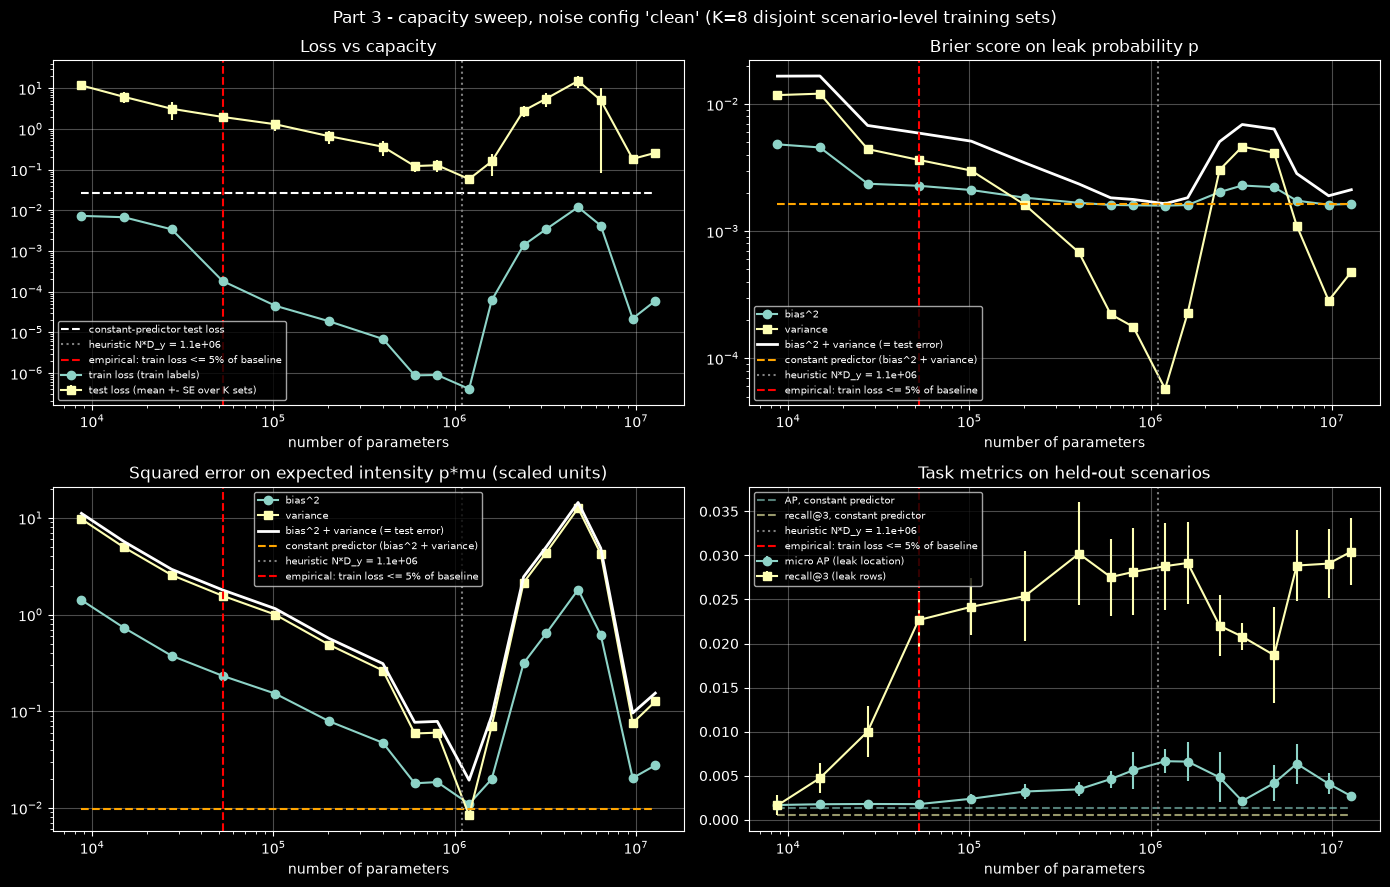


[clean] PEAK: test loss is highest at width 768 (4794804 params) and significantly lower at widths 192 and 1536 (> 2.0 SE).
 width  n_params  train_rel  test_rel  brier_bias2  brier_var  int_bias2  int_var       ap  recall3  n_retried  n_diverged
     1      8724     0.6163     430.9     0.004819    0.01176      1.415    9.753  0.00167 0.001632          0           0
     2     14964     0.5714     225.8     0.004557    0.01208      0.731    4.977 0.001758 0.004722          0           0
     4     27444     0.2878     114.9     0.002362   0.004425     0.3752    2.569 0.001788  0.01001          0           0
     8     52404    0.01548     72.27     0.002276   0.003639     0.2327    1.569 0.001771  0.02266          0           0
    16    102324    0.00381     47.82     0.002107   0.002999     0.1522    1.001  0.00238  0.02417          0           0
    32    202164   0.001587     24.37     0.001834   0.001612    0.07906   0.4894 0.003203  0.02538          0           0
    64    4018

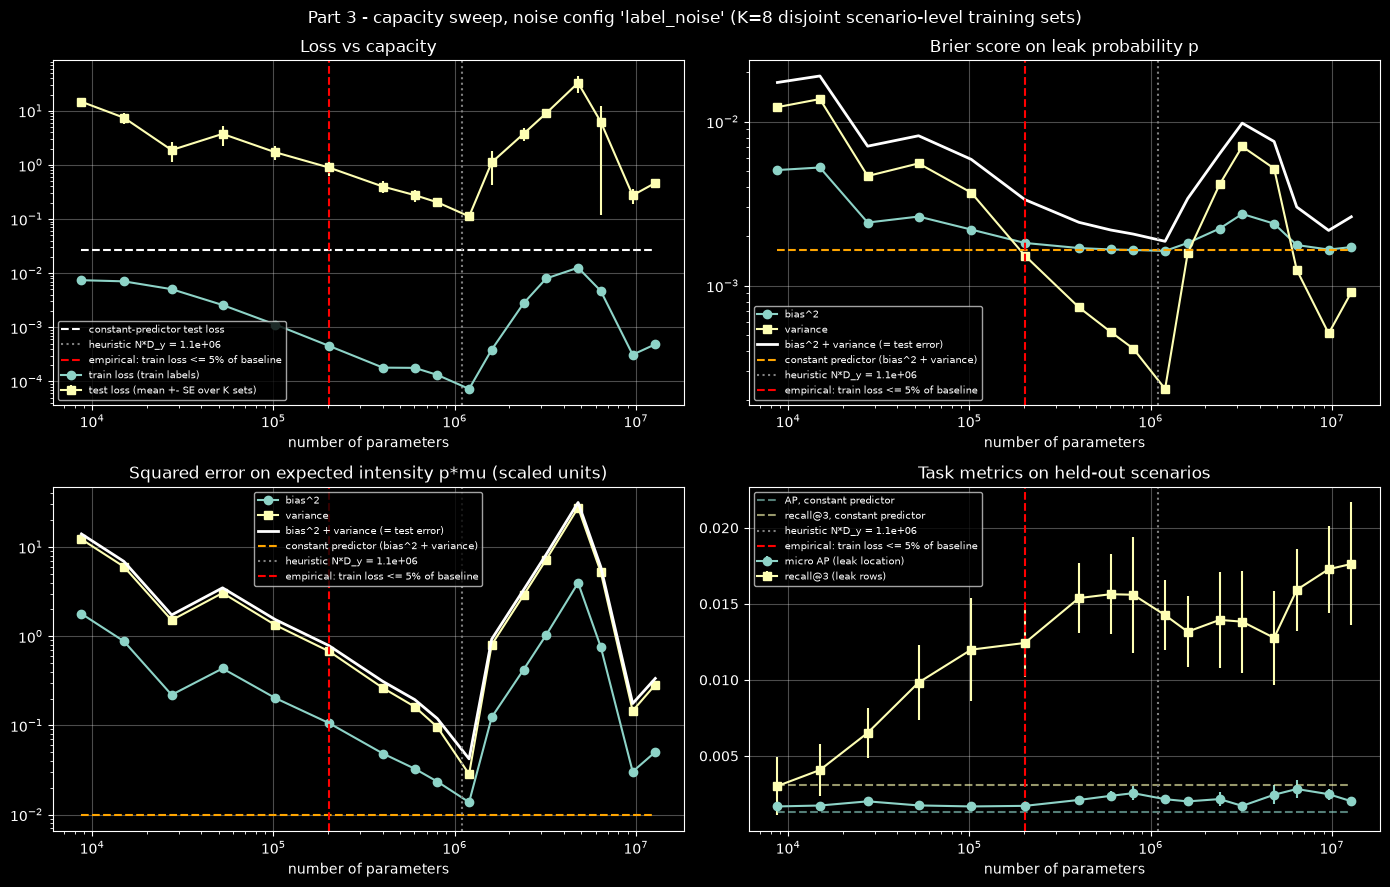


[label_noise] PEAK: test loss is highest at width 768 (4794804 params) and significantly lower at widths 192 and 1536 (> 2.0 SE).
 width  n_params  train_rel  test_rel  brier_bias2  brier_var  int_bias2  int_var       ap  recall3  n_retried  n_diverged
     1      8724     0.6279     538.9     0.005068    0.01226      1.785    12.23 0.001678 0.003021          0           0
     2     14964     0.5981     273.2     0.005252    0.01373     0.8774    6.024 0.001739 0.004074          0           0
     4     27444     0.4286     68.93     0.002425    0.00466       0.22    1.512 0.002013 0.006516          0           0
     8     52404     0.2187     137.3     0.002638   0.005562     0.4346    3.052 0.001745 0.009826          0           0
    16    102324    0.09528     62.78     0.002197   0.003691     0.2025    1.335 0.001679  0.01199          0           0
    32    202164    0.03849     32.84     0.001821   0.001525     0.1062   0.6787 0.001716  0.01243          0           0
    64  

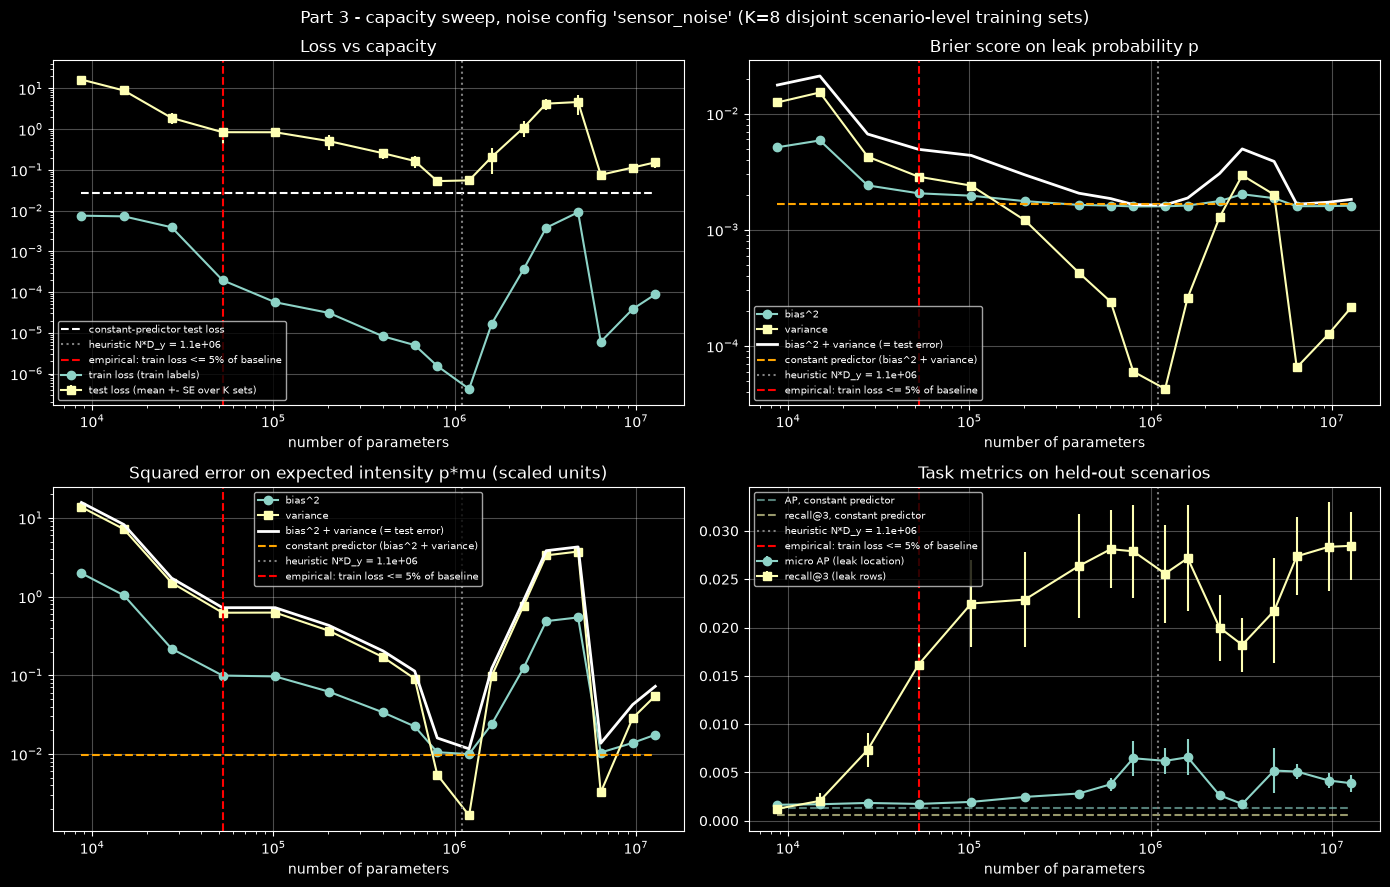


[sensor_noise] max test loss is at the sweep boundary (width 1): no interior peak.
 width  n_params  train_rel  test_rel  brier_bias2  brier_var  int_bias2  int_var       ap  recall3  n_retried  n_diverged
     1      8724     0.6334     601.1     0.005132    0.01249      1.978    13.72 0.001658 0.001238          0           0
     2     14964     0.6094     324.2     0.005873    0.01521      1.036    7.189  0.00171  0.00206          0           0
     4     27444     0.3287     68.81     0.002409    0.00426     0.2174    1.498 0.001846 0.007338          0           0
     8     52404    0.01652     30.71      0.00206   0.002863    0.09905   0.6231 0.001744  0.01617          0           0
    16    102324   0.004751     30.63     0.001964   0.002399    0.09655   0.6255 0.001954  0.02249          0           0
    32    202164   0.002609     18.59     0.001763   0.001207    0.06182   0.3682 0.002468  0.02289          0           0
    64    401844  0.0006953     9.383     0.001637  0.0

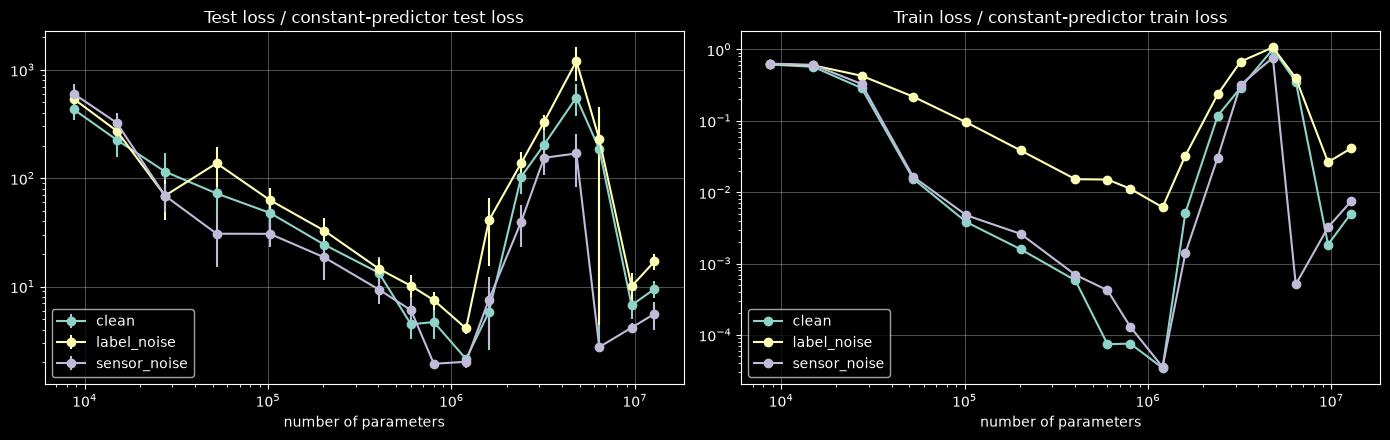

In [22]:
# ============================== 6. PART 3 - PLOTS, SUMMARY TABLE, PEAK CHECK ==============================
def _ms(vals):
    v = np.asarray(vals, dtype=float); return np.nanmean(v), (np.nanstd(v, ddof=1) / np.sqrt(np.sum(~np.isnan(v))) if np.sum(~np.isnan(v)) > 1 else 0.0)

def summarize(res):
    rows = []
    for w in sorted(res):
        r = res[w]; M = r["models"]
        g = lambda f: [f(m) for m in M]
        te, te_se = _ms(g(lambda m: m["test"]["loss"])); tr, _ = _ms(g(lambda m: m["train"]["loss"]))
        bte, _ = _ms(g(lambda m: m["base_test"]["loss"])); btr, _ = _ms(g(lambda m: m["base_train_loss"]))
        ap, ap_se = _ms(g(lambda m: m["test"]["ap"])); rc, rc_se = _ms(g(lambda m: m["test"]["recall3"]))
        bap, _ = _ms(g(lambda m: m["base_test"]["ap"])); brc, _ = _ms(g(lambda m: m["base_test"]["recall3"]))
        rows.append(dict(width=w, n_params=r["n_params"], n_train_rows=np.mean(g(lambda m: m["n_train_rows"])),
                         train_loss=tr, train_rel=tr / btr, test_loss=te, test_se=te_se, test_rel=te / bte, base_test=bte,
                         brier_bias2=r["bv_brier"]["bias2"], brier_var=r["bv_brier"]["variance"], brier_base=r["bv_brier_base"]["mse"],
                         int_bias2=r["bv_int"]["bias2"], int_var=r["bv_int"]["variance"], int_base=r["bv_int_base"]["mse"],
                         ap=ap, ap_se=ap_se, ap_base=bap, recall3=rc, recall3_se=rc_se, recall3_base=brc,
                         n_retried=sum(m["attempts"] > 1 for m in M), n_diverged=sum(m["diverged"] for m in M)))
    return pd.DataFrame(rows)

def peak_check(df, z=2.0):
    """Reports a test-loss peak only if some smaller and some larger model are BOTH lower than the peak by > z combined standard errors."""
    df = df[df["test_loss"].notna()].reset_index(drop=True)
    if len(df) < 3: return "fewer than 3 finite widths: no peak analysis possible."
    te, se = df["test_loss"].to_numpy(), df["test_se"].to_numpy(); i = int(np.argmax(te))
    if i == 0 or i == len(te) - 1: return f"max test loss is at the sweep boundary (width {df['width'].iloc[i]}): no interior peak."
    a = int(np.argmin(te[:i])); b = i + 1 + int(np.argmin(te[i + 1:]))
    sig = lambda j: te[i] - te[j] > z * np.hypot(se[i], se[j])
    if sig(a) and sig(b):
        return f"PEAK: test loss is highest at width {df['width'].iloc[i]} ({int(df['n_params'].iloc[i])} params) and significantly lower at widths {df['width'].iloc[a]} and {df['width'].iloc[b]} (> {z} SE)."
    return f"no significant interior peak (highest at width {df['width'].iloc[i]}; lower neighbours not separated by > {z} SE)."

SUMMARY = {}
for name, res in RESULTS.items():
    df = summarize(res); SUMMARY[name] = df
    x = df["n_params"].to_numpy(); n_rows_mean = df["n_train_rows"].mean()
    emp = df.loc[df["train_rel"] <= 0.05, "n_params"]
    fig, ax = plt.subplots(2, 2, figsize=(14, 9)); ax = ax.ravel()
    def marks(a):
        a.axvline(n_rows_mean * DATA["d_y"], color="grey", ls=":", label=f"heuristic N*D_y = {n_rows_mean * DATA['d_y']:.2g}")
        if len(emp): a.axvline(emp.iloc[0], color="red", ls="--", label="empirical: train loss <= 5% of baseline")
    ax[0].errorbar(x, df["train_loss"], fmt="o-", label="train loss (train labels)")
    ax[0].errorbar(x, df["test_loss"], yerr=df["test_se"], fmt="s-", label="test loss (mean +- SE over K sets)")
    ax[0].plot(x, df["base_test"], "w--", label="constant-predictor test loss"); marks(ax[0])
    ax[0].set_yscale("log"); ax[0].set_title("Loss vs capacity")
    for a, key, ttl in ((ax[1], "brier", "Brier score on leak probability p"), (ax[2], "int", "Squared error on expected intensity p*mu (scaled units)")):
        b2, vr, base = df[f"{key}_bias2"], df[f"{key}_var"], df[f"{key}_base"]
        a.plot(x, b2, "o-", label="bias^2"); a.plot(x, vr, "s-", label="variance"); a.plot(x, b2 + vr, "-", color="white", lw=2, label="bias^2 + variance (= test error)")
        a.plot(x, base, "--", color="orange", label="constant predictor (bias^2 + variance)"); marks(a); a.set_yscale("log"); a.set_title(ttl)
    ax[3].errorbar(x, df["ap"], yerr=df["ap_se"], fmt="o-", label="micro AP (leak location)")
    ax[3].errorbar(x, df["recall3"], yerr=df["recall3_se"], fmt="s-", label="recall@3 (leak rows)")
    ax[3].plot(x, df["ap_base"], "--", color="C0", alpha=.6, label="AP, constant predictor"); ax[3].plot(x, df["recall3_base"], "--", color="C1", alpha=.6, label="recall@3, constant predictor")
    marks(ax[3]); ax[3].set_title("Task metrics on held-out scenarios")
    for a in ax: a.set_xscale("log"); a.set_xlabel("number of parameters"); a.grid(True, alpha=.3); a.legend(fontsize=7)
    fig.suptitle(f"Part 3 - capacity sweep, noise config '{name}' (K={K_SETS} disjoint scenario-level training sets)"); fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, f"part3_{name}.png"), dpi=150); plt.show()
    print(f"\n[{name}] {peak_check(df)}")
    print(df[["width", "n_params", "train_rel", "test_rel", "brier_bias2", "brier_var", "int_bias2", "int_var", "ap", "recall3", "n_retried", "n_diverged"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"))

if len(SUMMARY) > 1:
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    for name, df in SUMMARY.items():
        ax[0].errorbar(df["n_params"], df["test_rel"], yerr=df["test_se"] / df["base_test"], fmt="o-", label=name)
        ax[1].plot(df["n_params"], df["train_rel"], "o-", label=name)
    ax[0].set_title("Test loss / constant-predictor test loss"); ax[1].set_title("Train loss / constant-predictor train loss")
    for a in ax: a.set_xscale("log"); a.set_yscale("log"); a.set_xlabel("number of parameters"); a.grid(True, alpha=.3); a.legend()
    fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "part3_overlay.png"), dpi=150); plt.show()


## 7. Part 4A — forward / backward propagation vs. initialisation scale and depth

In [23]:
# ============================== 7. PART 4A - FORWARD / BACKWARD PROPAGATION vs INIT SCALE AND DEPTH (at initialisation) ==============================
# ReLU network, width W, depth L, weights ~ N(0, c * 2/fan_in).  c = 1 is He init (variance-preserving), c < 1 shrinks, c > 1 inflates the signal.
# Mean-field theory for ReLU:  E[h_{k+1}^2] = c * E[h_k^2]  (forward)   and   E[delta_k^2] = c * E[delta_{k+1}^2]  (backward, delta = dLoss/d pre-activation).
# Measured in float64 so that c^L never under/overflows; "RMS" = root-mean-square over batch x units (or matrix entries).
POOL_IDX = torch.as_tensor(DATA["pool_rows"], device=device)
POOL_X, POOL_Y = DATA["x"][POOL_IDX], DATA["y"][POOL_IDX]

def fwd_bwd_stats(depth, width, var_mult, seed, batch=64, dtype=torch.float64):
    torch.manual_seed(seed)
    model = DNN(DATA["d_in"], [width] * depth, 2 * DATA["d_y"], dtype=dtype)
    init_params(model, var_mult)
    g = torch.Generator(device="cpu"); g.manual_seed(seed)
    idx = torch.randperm(len(POOL_X), generator=g)[:batch].to(device)
    x, y = POOL_X[idx].to(dtype), POOL_Y[idx].to(dtype)
    pre, h = [], x
    for layer in model:                                   # manual forward so that every pre-activation can keep its gradient
        h = layer(h)
        if isinstance(layer, nn.Linear): h.retain_grad(); pre.append(h)
    loss = leak_loss_from_output(h, y); loss.backward()
    lin = [m for m in model if isinstance(m, nn.Linear)]
    rms = lambda t: t.detach().pow(2).mean().sqrt().item()
    return dict(fwd=[rms(p) for p in pre], bwd=[rms(p.grad) for p in pre], wgrad=[rms(m.weight.grad) for m in lin])

def geo_mean(rows):                                       # geometric mean over repeats, element-wise
    a = np.log(np.maximum(np.asarray(rows, dtype=float), 1e-300)); return np.exp(a.mean(0))

P4A = {}
t0 = time.time()
for L in CFG["p4_depths"]:
    for c in CFG["p4_var_mults"]:
        reps = [fwd_bwd_stats(L, CFG["p4_width"], c, seed=SEED + 17 * r + L) for r in range(CFG["p4_repeats"])]
        P4A[(L, c)] = {k: geo_mean([r[k] for r in reps]) for k in ("fwd", "bwd", "wgrad")}
print(f"Part 4A: {len(P4A)} (depth, init-scale) settings measured in {time.time() - t0:.0f}s")


Part 4A: 30 (depth, init-scale) settings measured in 2s


## 8. Part 4A — plots

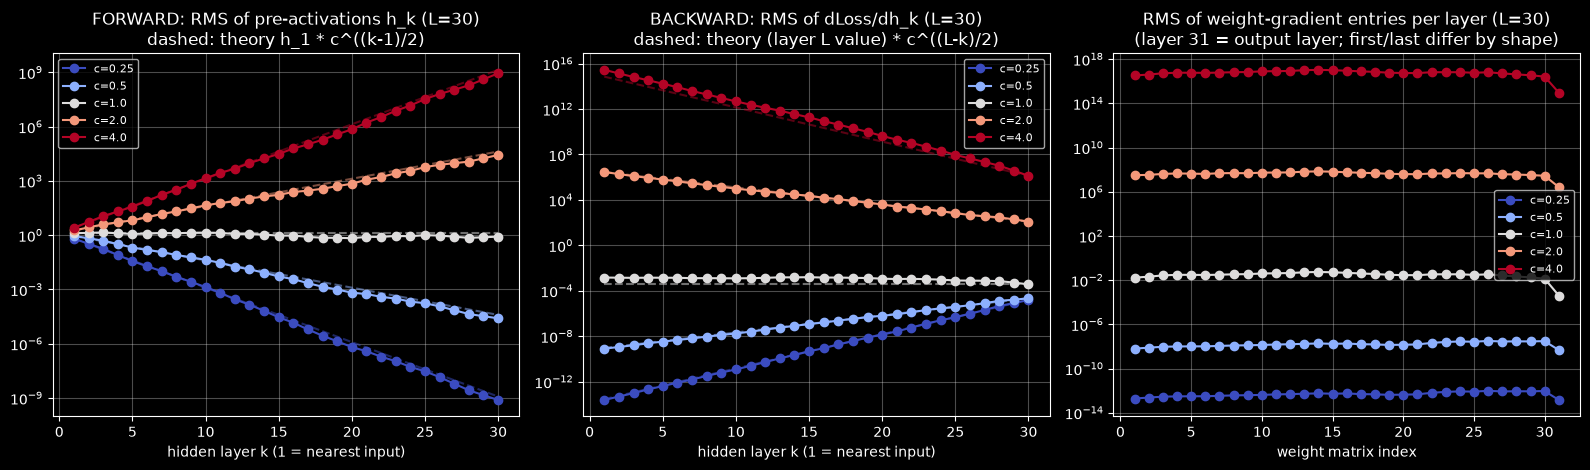

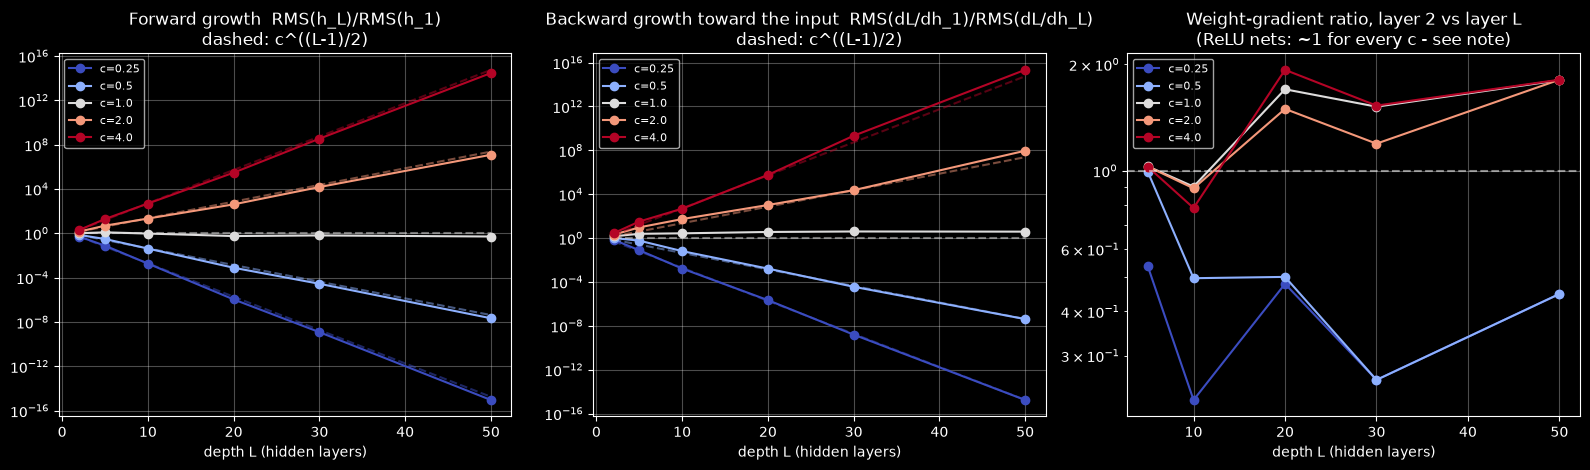

Reading guide: for c < 1 the forward signal and the backprop signal both decay exponentially with depth (vanishing); for c > 1 both grow (exploding); c = 1 (He) keeps them ~flat. Because a ReLU net is positively homogeneous, the per-layer weight gradient dL/dW_k = delta_k * a_(k-1) stays balanced across layers for every c, but its overall scale changes with c^(L/2) - that overall scale is what the optimizer comparison in 4B probes.


In [24]:
# ============================== 8. PART 4A - PLOTS ==============================
cs = CFG["p4_var_mults"]; colors = {c: plt.cm.coolwarm(i / max(1, len(cs) - 1)) for i, c in enumerate(cs)}
Ls = CFG["p4_show_depth"] if CFG["p4_show_depth"] in CFG["p4_depths"] else CFG["p4_depths"][-1]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8)); ks = np.arange(1, Ls + 1)
for c in cs:
    d = P4A[(Ls, c)]
    ax[0].plot(ks, d["fwd"][:Ls], "o-", color=colors[c], label=f"c={c}")
    ax[0].plot(ks, d["fwd"][0] * c ** ((ks - 1) / 2), "--", color=colors[c], alpha=.5)
    ax[1].plot(ks, d["bwd"][:Ls], "o-", color=colors[c], label=f"c={c}")
    ax[1].plot(ks, d["bwd"][Ls - 1] * c ** ((Ls - ks) / 2), "--", color=colors[c], alpha=.5)
    ax[2].plot(np.arange(1, Ls + 2), d["wgrad"], "o-", color=colors[c], label=f"c={c}")
ax[0].set_title(f"FORWARD: RMS of pre-activations h_k (L={Ls})\ndashed: theory h_1 * c^((k-1)/2)")
ax[1].set_title(f"BACKWARD: RMS of dLoss/dh_k (L={Ls})\ndashed: theory (layer L value) * c^((L-k)/2)")
ax[2].set_title(f"RMS of weight-gradient entries per layer (L={Ls})\n(layer {Ls + 1} = output layer; first/last differ by shape)")
for a, xl in zip(ax, ("hidden layer k (1 = nearest input)",) * 2 + ("weight matrix index",)):
    a.set_yscale("log"); a.set_xlabel(xl); a.grid(True, alpha=.3); a.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "part4a_layerwise.png"), dpi=150); plt.show()

Ld = CFG["p4_depths"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for c in cs:
    fr = [P4A[(L, c)]["fwd"][L - 1] / P4A[(L, c)]["fwd"][0] for L in Ld]               # h_L / h_1
    br = [P4A[(L, c)]["bwd"][0] / P4A[(L, c)]["bwd"][L - 1] for L in Ld]               # dLoss/dh_1 / dLoss/dh_L
    wr = [P4A[(L, c)]["wgrad"][1] / P4A[(L, c)]["wgrad"][L - 1] if L > 2 else np.nan for L in Ld]   # hidden-to-hidden layers only (2 vs L)
    th = [c ** ((L - 1) / 2) for L in Ld]
    ax[0].plot(Ld, fr, "o-", color=colors[c], label=f"c={c}"); ax[0].plot(Ld, th, "--", color=colors[c], alpha=.5)
    ax[1].plot(Ld, br, "o-", color=colors[c], label=f"c={c}"); ax[1].plot(Ld, th, "--", color=colors[c], alpha=.5)
    ax[2].plot(Ld, wr, "o-", color=colors[c], label=f"c={c}")
ax[2].axhline(1.0, color="white", ls="--", alpha=.5)
ax[0].set_title("Forward growth  RMS(h_L)/RMS(h_1)\ndashed: c^((L-1)/2)"); ax[1].set_title("Backward growth toward the input  RMS(dL/dh_1)/RMS(dL/dh_L)\ndashed: c^((L-1)/2)")
ax[2].set_title("Weight-gradient ratio, layer 2 vs layer L\n(ReLU nets: ~1 for every c - see note)")
for a in ax: a.set_yscale("log"); a.set_xlabel("depth L (hidden layers)"); a.grid(True, alpha=.3); a.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "part4a_depth_scaling.png"), dpi=150); plt.show()
print("Reading guide: for c < 1 the forward signal and the backprop signal both decay exponentially with depth (vanishing); for c > 1 both grow (exploding); "
      "c = 1 (He) keeps them ~flat. Because a ReLU net is positively homogeneous, the per-layer weight gradient dL/dW_k = delta_k * a_(k-1) stays balanced across "
      "layers for every c, but its overall scale changes with c^(L/2) - that overall scale is what the optimizer comparison in 4B probes.")


## 9. Part 4B — SGD vs. Adam under mis-scaled initialisation

C:\Users\akash\AppData\Local\Temp\ipykernel_31232\1094159347.py:145: UserWarning: sgd: best learning rate is at the upper edge of the stable search range. Consider extending the grid.
  warnings.warn(


tuned at He init: SGD lr=0.1 | Adam lr=0.03162277660168379
SGD scores: {1e-06: np.float64(1.0874969720840455), 3.162277660168379e-06: np.float64(1.0479666973153752), 1e-05: np.float64(0.9700423985719682), 3.1622776601683795e-05: np.float64(0.868226824204127), 0.0001: np.float64(0.7802864089608192), 0.00031622776601683794: np.float64(0.7292603135108949), 0.001: np.float64(0.7075566276907921), 0.0031622776601683794: np.float64(0.7001633400718372), 0.01: np.float64(0.6971461668610573), 0.03162277660168379: np.float64(0.6943549722433091), 0.1: np.float64(0.6880536720156668), 0.31622776601683794: inf, 1.0: inf, 10.0: inf, 100.0: inf}
Adam scores: {1e-06: np.float64(0.8810199161370594), 3.162277660168379e-06: np.float64(0.76756030023098), 1e-05: np.float64(0.7076383233070374), 3.1622776601683795e-05: np.float64(0.6720539058248202), 0.0001: np.float64(0.04905061889439821), 0.0003: np.float64(0.013046485449497899), 0.00031622776601683794: np.float64(0.012769931190026304), 0.001: np.float64(0.0

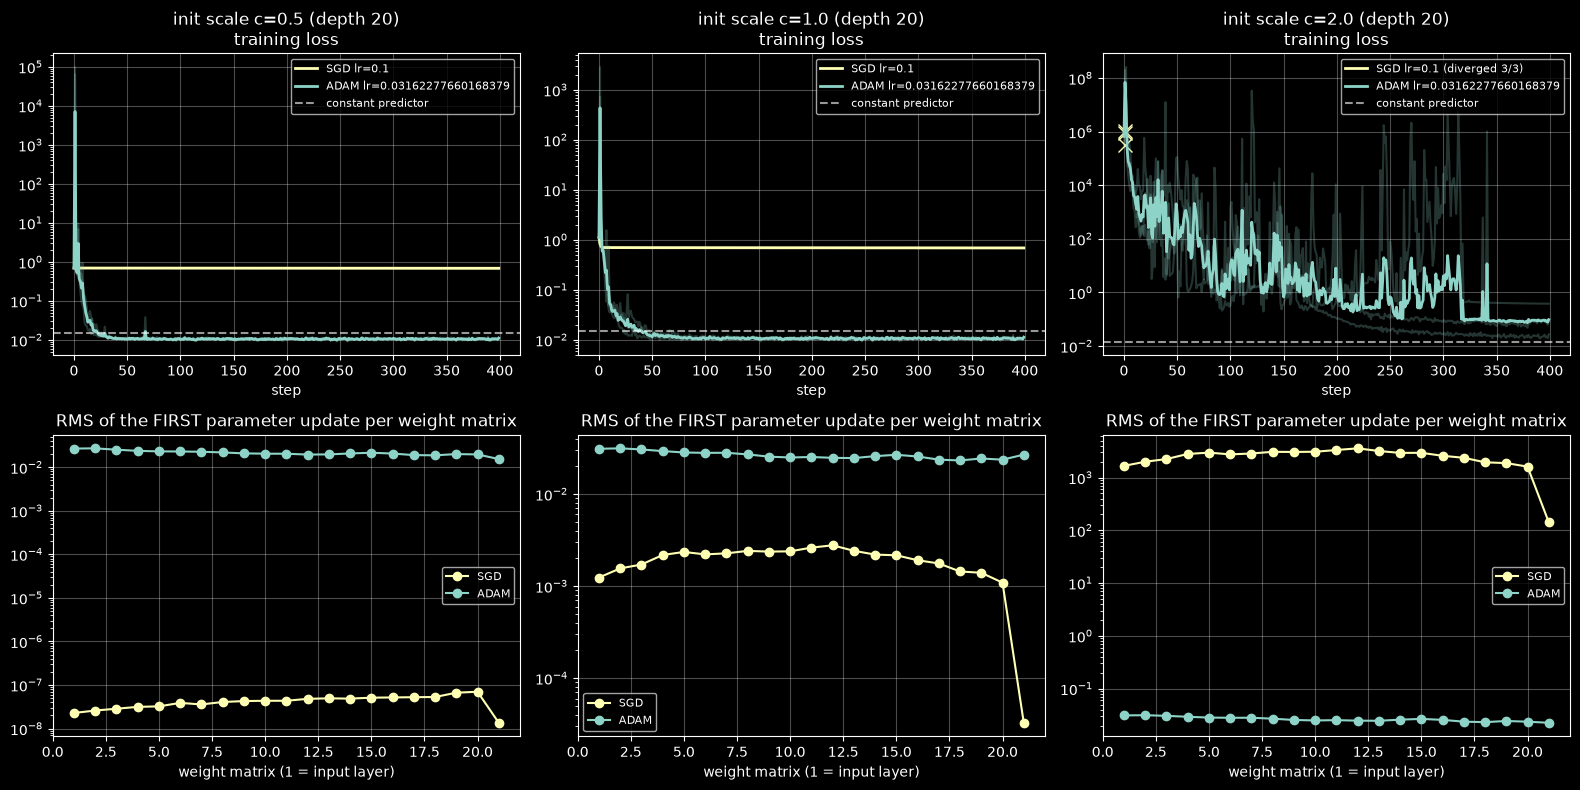

Reading guide: SGD's step is lr * gradient, so its update size follows the gradient scale (tiny for c<1, huge/diverging for c>1). Adam divides by sqrt(v), so its first update is approximately lr per parameter, largely insensitive to gradient magnitude (but not to the eps floor: gradients below ~1e-8 are not rescaled).


In [25]:

# ============================== 9. PART 4B - OPTIMIZER CHOICE UNDER MIS-SCALED INITIALISATION ==============================
# Protocol:
# 1. Tune each optimizer's learning rate ONCE at He init (c = 1).
# 2. Keep it fixed when re-initialising with c < 1 and c > 1.
# 3. Use the same minibatch stream for both optimizers.
# 4. Clipping is OFF. Precision is float32.

base_pool = fit_constant_baseline(POOL_Y)
_ybase = POOL_Y[
    torch.randperm(
        len(POOL_Y),
        generator=torch.Generator().manual_seed(0)
    )[:4096].to(device)
]
BASELINE_LOSS = leak_loss_from_output(
    baseline_output(base_pool, len(_ybase)), _ybase
).item()


def run_4b(opt_name, lr, var_mult, seed, depth=None, steps=None,
           width=None, batch=64):

    depth = depth or CFG["p4b_depth"]
    steps = steps or CFG["p4b_steps"]
    width = width or CFG["p4_width"]

    torch.manual_seed(seed)

    model = DNN(DATA["d_in"], [width] * depth, 2 * DATA["d_y"])
    init_params(model, var_mult)

    params = list(model.parameters())
    opt = make_optimizer(opt_name, params, lr)

    g = torch.Generator(device=device)
    g.manual_seed(seed)

    losses = []
    diverged_at = None
    first_upd = None
    first_grad = None

    for t in range(steps):

        idx = torch.randint(
            0, len(POOL_X), (batch,),
            device=device, generator=g
        )

        loss = leak_loss_from_output(
            model(POOL_X[idx]), POOL_Y[idx]
        )

        if not torch.isfinite(loss).item():
            diverged_at = t
            break

        grads = torch.autograd.grad(loss, params)

        if t == 0:
            before = [p.detach().clone() for p in params]

        opt.step(grads)

        if t == 0:
            first_upd = [
                (p.detach() - b).pow(2).mean().sqrt().item()
                for p, b in zip(params, before) if p.dim() == 2
            ]

            first_grad = [
                gr.pow(2).mean().sqrt().item()
                for gr, p in zip(grads, params) if p.dim() == 2
            ]

        losses.append(loss.item())

    if diverged_at is None and not all(np.isfinite(l) for l in losses):
        diverged_at = int(np.argmax(~np.isfinite(losses)))

    return dict(
        losses=np.array(losses),
        diverged_at=diverged_at,
        first_upd=first_upd,
        first_grad=first_grad
    )


def tune_lr(opt_name, grid):

    # Try the configured grid first.
    candidates = list(grid)

    # If unstable, expand the search towards smaller learning rates.
    if opt_name.lower() == "sgd":
        fallback = np.logspace(-6, 0, 13)
    elif opt_name.lower() == "adam":
        fallback = np.logspace(-6, 1, 15)
    else:
        fallback = np.logspace(-6, 0, 13)

    candidates = sorted(set(candidates + fallback.tolist()))

    scores = {}
    stable_candidates = []

    for lr in candidates:

        runs = [
            run_4b(
                opt_name, lr, 1.0,
                seed=SEED + s
            )
            for s in range(CFG["p4b_seeds"])
        ]

        ok = all(r["diverged_at"] is None for r in runs)

        if ok and all(len(r["losses"]) > 0 for r in runs):

            score = np.mean([
                r["losses"][
                    -max(5, CFG["p4b_steps"] // 10):
                ].mean()
                for r in runs
            ])

            scores[lr] = score

            if np.isfinite(score):
                stable_candidates.append(lr)

        else:
            scores[lr] = np.inf

    if not stable_candidates:
        raise RuntimeError(
            f"No stable {opt_name} learning rate found. "
            f"Try extending the fallback grid towards smaller values."
        )

    best = min(stable_candidates, key=lambda lr: scores[lr])

    if best == max(stable_candidates):
        warnings.warn(
            f"{opt_name}: best learning rate is at the upper edge "
            "of the stable search range. Consider extending the grid."
        )

    return best, scores


# Tune learning rates ONCE at He initialization.
LR_SGD, sc_sgd = tune_lr("sgd", CFG["p4b_sgd_lrs"])
LR_ADAM, sc_adam = tune_lr("adam", CFG["p4b_adam_lrs"])

print(
    f"tuned at He init: "
    f"SGD lr={LR_SGD} | Adam lr={LR_ADAM}"
)
print(f"SGD scores: {sc_sgd}")
print(f"Adam scores: {sc_adam}")
print(f"constant-predictor loss = {BASELINE_LOSS:.4g}")


# Evaluate both optimizers at all initialization scales.
P4B = {
    (c, o): [
        run_4b(o, lr, c, seed=SEED + s)
        for s in range(CFG["p4b_seeds"])
    ]
    for c in CFG["p4b_var_mults"]
    for o, lr in (("sgd", LR_SGD), ("adam", LR_ADAM))
}


# Plot results.
cs4 = CFG["p4b_var_mults"]

fig, ax = plt.subplots(
    2, len(cs4),
    figsize=(5.3 * len(cs4), 8),
    squeeze=False
)

for j, c in enumerate(cs4):

    for o, col in (("sgd", "C1"), ("adam", "C0")):

        runs = P4B[(c, o)]

        for r in runs:
            ax[0, j].plot(
                np.arange(len(r["losses"])),
                r["losses"],
                color=col,
                alpha=.25
            )

        n_ok = min(len(r["losses"]) for r in runs)

        m = np.exp(
            np.mean(
                [
                    np.log(np.maximum(r["losses"][:n_ok], 1e-30))
                    for r in runs
                ],
                0
            )
        )

        n_div = sum(
            r["diverged_at"] is not None for r in runs
        )

        lr = LR_SGD if o == "sgd" else LR_ADAM

        ax[0, j].plot(
            np.arange(n_ok),
            m,
            color=col,
            lw=2,
            label=f"{o.upper()} lr={lr}"
            + (f" (diverged {n_div}/{len(runs)})" if n_div else "")
        )

        for r in runs:
            if r["diverged_at"] is not None:
                ax[0, j].plot(
                    [r["diverged_at"]],
                    [r["losses"][-1] if len(r["losses"]) else 1],
                    "x", color=col, ms=10
                )

        fu = [
            r["first_upd"] for r in runs
            if r["first_upd"] is not None
        ]

        if fu:
            ax[1, j].plot(
                np.arange(1, len(fu[0]) + 1),
                np.exp(
                    np.mean(
                        np.log(np.maximum(fu, 1e-300)),
                        0
                    )
                ),
                "o-",
                color=col,
                label=o.upper()
            )

    ax[0, j].axhline(
        BASELINE_LOSS,
        color="white",
        ls="--",
        alpha=.6,
        label="constant predictor"
    )

    ax[0, j].set_yscale("log")
    ax[0, j].set_title(
        f"init scale c={c} (depth {CFG['p4b_depth']})\ntraining loss"
    )
    ax[0, j].set_xlabel("step")
    ax[0, j].legend(fontsize=8)

    ax[1, j].set_yscale("log")
    ax[1, j].set_title(
        "RMS of the FIRST parameter update per weight matrix"
    )
    ax[1, j].set_xlabel("weight matrix (1 = input layer)")
    ax[1, j].legend(fontsize=8)

    for a in ax[:, j]:
        a.grid(True, alpha=.3)

fig.tight_layout()
fig.savefig(
    os.path.join(OUT_DIR, "part4b_optimizers.png"),
    dpi=150
)
plt.show()

print(
    "Reading guide: SGD's step is lr * gradient, so its update size "
    "follows the gradient scale (tiny for c<1, huge/diverging for c>1). "
    "Adam divides by sqrt(v), so its first update is approximately lr "
    "per parameter, largely insensitive to gradient magnitude "
    "(but not to the eps floor: gradients below ~1e-8 are not rescaled)."
)

## 10. Part 5 — implicit regularisation: core tools

In [26]:
# ============================== 10. PART 5 - IMPLICIT REGULARISATION (UDL 9.2): CORE TOOLS ==============================
# Theory (backward error analysis, first order in the step size alpha):
#   GD     : phi_{n+1} = phi_n - alpha * grad L          follows the flow of   L~_GD  = L + (alpha/4) * ||grad L||^2          (not the flow of L)
#   SGD    : fixed partition into B batches, batch ORDER shuffled every epoch; the MEAN iterate after each epoch (time = B*alpha per epoch) follows the flow of
#            L~_SGD = L + (alpha/4)||grad L||^2 + (alpha/(4B)) * sum_b ||grad L_b - grad L||^2  =  L + (alpha/(4B)) * sum_b ||grad L_b||^2   (identity: sum_b grad L_b = B grad L)
# Checks done below: error(GD, flow of L) = O(alpha) while error(GD, flow of L~) = O(alpha^2).  Everything is float64, smooth losses only
# (ReLU makes grad L discontinuous, so the smooth-flow analysis does not apply to it - the leak-network test in 5B therefore uses tanh).
F64 = torch.float64                   # every Part 5 tensor is created in float64 explicitly (no global default change)
P5_DEV = torch.device("cpu")          # toy problems are tiny -> CPU; the leak-network test (5B) moves to `device`

class Problem:
    """loss(phi, idx) = mean loss over the rows in idx (None = all rows); phi is a flat float64 vector."""
    def __init__(self, loss, n_rows, phi0, name): self.loss, self.n, self.phi0, self.name = loss, n_rows, phi0, name

def grad_at(prob, phi, idx=None):
    with torch.enable_grad():
        p = phi.detach().requires_grad_(True)
        g, = torch.autograd.grad(prob.loss(p, idx), p)
    return g.detach()

def sharpness(prob, phi, iters=100, seed=0):
    """Largest |eigenvalue| of the Hessian of the full loss at phi (power iteration with Hessian-vector products)."""
    gen = torch.Generator(device="cpu"); gen.manual_seed(seed)
    v = torch.randn(phi.numel(), generator=gen, dtype=phi.dtype).to(phi.device); v /= v.norm(); lam = 0.0
    for _ in range(iters):
        with torch.enable_grad():
            p = phi.detach().requires_grad_(True)
            g, = torch.autograd.grad(prob.loss(p), p, create_graph=True)
            hv, = torch.autograd.grad((g * v).sum(), p)
        lam = hv.norm().item(); v = hv.detach() / (lam + 1e-300)
    return lam

def vf_flow(prob):                                    # d phi/dt = -grad L
    return lambda t, phi: -grad_at(prob, phi)

def vf_mod_gd(prob, alpha):                           # d phi/dt = -grad [ L + (alpha/4) ||grad L||^2 ]
    def f(t, phi):
        with torch.enable_grad():
            p = phi.detach().requires_grad_(True)
            L = prob.loss(p); g, = torch.autograd.grad(L, p, create_graph=True)
            gt, = torch.autograd.grad(L + 0.25 * alpha * (g * g).sum(), p)
        return -gt.detach()
    return f

def vf_mod_sgd(prob, alpha, batches):                 # d phi/dt = -grad [ L + (alpha/(4B)) sum_b ||grad L_b||^2 ]
    B = len(batches)
    def f(t, phi):
        with torch.enable_grad():
            p = phi.detach().requires_grad_(True)
            L = prob.loss(p); pen = 0.0
            for b in batches:
                gb, = torch.autograd.grad(prob.loss(p, b), p, create_graph=True); pen = pen + (gb * gb).sum()
            gt, = torch.autograd.grad(L + alpha / (4 * B) * pen, p)
        return -gt.detach()
    return f

def solve(vf, phi0, times, rtol=1e-10, atol=1e-12):
    return odeint(vf, phi0, times, rtol=rtol, atol=atol, method="dopri5")        # shape (len(times), P)

def run_gd(prob, alpha, n_steps, record_steps):
    phi, out, rec = prob.phi0.clone(), {}, set(record_steps)
    for n in range(1, n_steps + 1):
        phi = phi - alpha * grad_at(prob, phi)
        if n in rec: out[n] = phi.clone()
    return out

def loglog_slope(alphas, errs):
    a, e = np.log(np.asarray(alphas)), np.log(np.maximum(np.asarray(errs), 1e-300)); return np.polyfit(a, e, 1)[0]

# ---------------- 2-parameter toy: f(x; phi) = phi0 + sin(phi1 * x), per-example loss (f - y)^2 ----------------
def toy_f(phi, x): return phi[..., 0:1] + torch.sin(phi[..., 1:2] * x)
_g = torch.Generator().manual_seed(3)
TOY_N, TOY_B = 16, 4
TOY_X = torch.linspace(-1, 1, TOY_N, dtype=F64)
TOY_Y = toy_f(torch.tensor([0.3, 1.2], dtype=F64), TOY_X) + 0.2 * torch.randn(TOY_N, generator=_g, dtype=F64)
def toy_loss(phi, idx=None):
    x, y = (TOY_X, TOY_Y) if idx is None else (TOY_X[idx], TOY_Y[idx])
    return ((toy_f(phi, x) - y) ** 2).mean()
TOY = Problem(toy_loss, TOY_N, torch.tensor([-0.5, 0.8], dtype=F64), "toy")
TOY_BATCHES = torch.randperm(TOY_N, generator=torch.Generator().manual_seed(5)).view(TOY_B, -1)    # FIXED partition

# sanity: identity used for L~_SGD, and analytic-vs-autograd consistency of the toy
_p = TOY.phi0.clone(); _gfull = grad_at(TOY, _p); _gb = [grad_at(TOY, _p, b) for b in TOY_BATCHES]
_lhs = sum((gb * gb).sum() for gb in _gb) / TOY_B
_rhs = (_gfull * _gfull).sum() + sum(((gb - _gfull) ** 2).sum() for gb in _gb) / TOY_B
assert abs(_lhs - _rhs) < 1e-12, "identity (1/B) sum||g_b||^2 = ||g||^2 + (1/B) sum||g_b - g||^2 failed"
print("Part 5 core ready. toy sharpness at phi0 =", round(sharpness(TOY, TOY.phi0), 4))


Part 5 core ready. toy sharpness at phi0 = 2.0


## 11. Part 5A — GD vs. flow(L) vs. flow(L̃) on a 2-parameter toy

    alpha  n_steps  |GD - flow(L)|  |GD - flow(L~_GD)|
1.250e-01       14       1.145e-02           1.405e-03
6.250e-02       28       5.874e-03           4.032e-04
3.125e-02       56       2.970e-03           1.075e-04
1.562e-02      112       1.493e-03           2.775e-05
7.812e-03      224       7.482e-04           7.045e-06
3.906e-03      448       3.745e-04           1.775e-06
log-log slope in alpha (3 smallest alphas): vs flow(L) = 1.00  (theory: 1)   |   vs flow(L~_GD) = 1.97  (theory: >= 2)


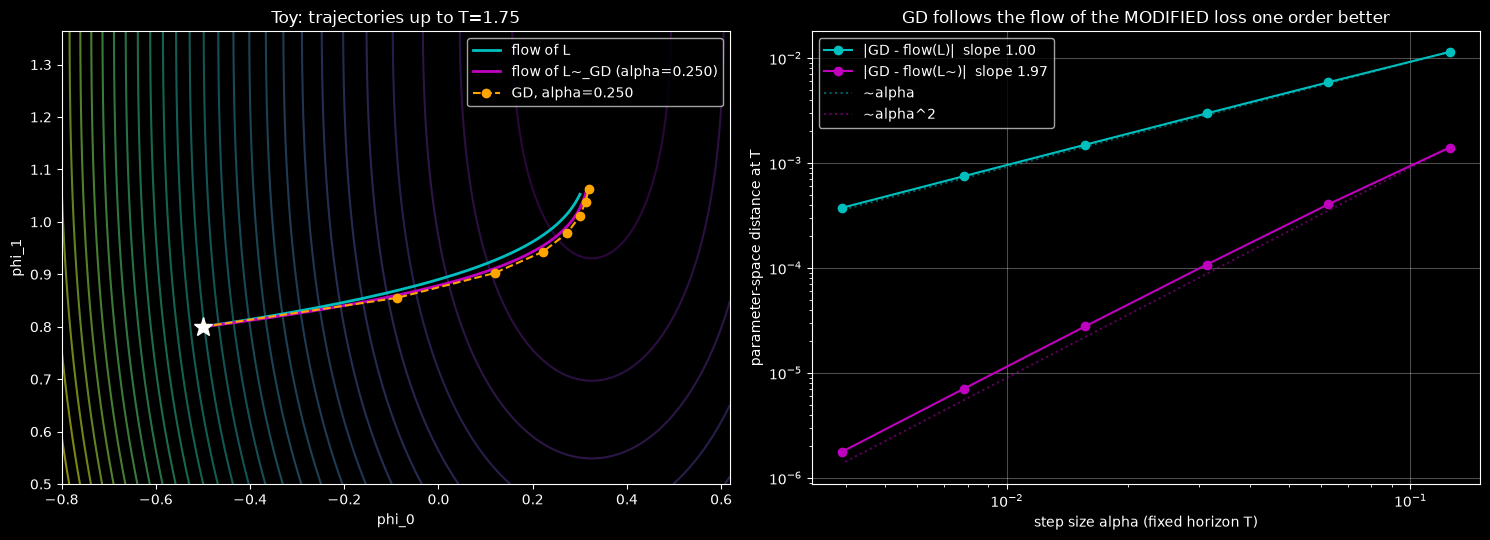

In [27]:
# ============================== 11. PART 5A - GD vs GRADIENT FLOW vs MODIFIED FLOW (2-parameter toy) ==============================
lam0   = sharpness(TOY, TOY.phi0)
alpha0 = 0.25 / lam0                                   # largest step size used (alpha * lambda_max = 0.25 at phi0)
n_alpha, n0_steps = 6, 14                              # alpha_k = alpha0/2^k ;  horizon T = 14 * alpha0 for every k
T5A  = n0_steps * alpha0
alphas_5a = [alpha0 / 2 ** k for k in range(n_alpha)]
t2 = torch.tensor([0.0, T5A], dtype=F64)
flowL = solve(vf_flow(TOY), TOY.phi0, t2)[-1]
rows = []
for a in alphas_5a:
    n = int(round(T5A / a)); phi_gd = run_gd(TOY, a, n, [n])[n]
    flowM = solve(vf_mod_gd(TOY, a), TOY.phi0, t2)[-1]
    rows.append((a, n, (phi_gd - flowL).norm().item(), (phi_gd - flowM).norm().item()))
df5a = pd.DataFrame(rows, columns=["alpha", "n_steps", "|GD - flow(L)|", "|GD - flow(L~_GD)|"])
print(df5a.to_string(index=False, float_format=lambda v: f"{v:.3e}"))
s1 = loglog_slope(alphas_5a[2:], df5a.iloc[2:, 2]); s2 = loglog_slope(alphas_5a[2:], df5a.iloc[2:, 3])
print(f"log-log slope in alpha (3 smallest alphas): vs flow(L) = {s1:.2f}  (theory: 1)   |   vs flow(L~_GD) = {s2:.2f}  (theory: >= 2)")

# trajectory picture for a large alpha (UDL Fig. 9.1 style)
a_big = alpha0 * 2; n_big = int(round(T5A / a_big))
gd_path = [TOY.phi0.clone()]; p = TOY.phi0.clone()
for _ in range(n_big): p = p - a_big * grad_at(TOY, p); gd_path.append(p.clone())
gd_path = torch.stack(gd_path); tt = torch.linspace(0, T5A, 200, dtype=F64)
pathL, pathM = solve(vf_flow(TOY), TOY.phi0, tt), solve(vf_mod_gd(TOY, a_big), TOY.phi0, tt)
allp = torch.cat([gd_path, pathL, pathM]); lo, hi = allp.min(0).values - 0.3, allp.max(0).values + 0.3
g0, g1 = torch.meshgrid(torch.linspace(lo[0].item(), hi[0].item(), 120, dtype=F64), torch.linspace(lo[1].item(), hi[1].item(), 120, dtype=F64), indexing="ij")
Lgrid = torch.stack([toy_loss(torch.stack([a, b])) for a, b in zip(g0.flatten(), g1.flatten())]).view(120, 120)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
ax[0].contour(g0, g1, Lgrid, 30, cmap="viridis", alpha=.6)
ax[0].plot(*pathL.T, "c-", lw=2, label="flow of L"); ax[0].plot(*pathM.T, "m-", lw=2, label=f"flow of L~_GD (alpha={a_big:.3f})")
ax[0].plot(*gd_path.T, "o--", color="orange", label=f"GD, alpha={a_big:.3f}"); ax[0].plot(*TOY.phi0, "w*", ms=14)
ax[0].set_xlabel("phi_0"); ax[0].set_ylabel("phi_1"); ax[0].legend(); ax[0].set_title(f"Toy: trajectories up to T={T5A:.2f}")
ax[1].loglog(alphas_5a, df5a.iloc[:, 2], "co-", label=f"|GD - flow(L)|  slope {s1:.2f}"); ax[1].loglog(alphas_5a, df5a.iloc[:, 3], "mo-", label=f"|GD - flow(L~)|  slope {s2:.2f}")
ax[1].loglog(alphas_5a, df5a.iloc[0, 2] * np.array(alphas_5a) / alphas_5a[0], "c:", alpha=.5, label="~alpha"); ax[1].loglog(alphas_5a, df5a.iloc[0, 3] * (np.array(alphas_5a) / alphas_5a[0]) ** 2, "m:", alpha=.5, label="~alpha^2")
ax[1].set_xlabel("step size alpha (fixed horizon T)"); ax[1].set_ylabel("parameter-space distance at T"); ax[1].legend(); ax[1].grid(True, alpha=.3)
ax[1].set_title("GD follows the flow of the MODIFIED loss one order better")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "part5a_gd_toy.png"), dpi=150); plt.show()


## 12. Part 5C — SGD (mean over shuffles) vs. the three flows on the toy

    alpha  epochs  |SGD mean - flow(L)|  |SGD mean - flow(L~_GD)|  |SGD mean - flow(L~_SGD)|  std.err. of mean
2.000e-01       5             2.485e-02                 1.802e-02                  5.600e-04         4.613e-05
1.000e-01      10             1.281e-02                 9.334e-03                  8.978e-05         1.520e-05
5.000e-02      20             6.546e-03                 4.791e-03                  1.988e-05         5.127e-06
2.500e-02      40             3.314e-03                 2.432e-03                  6.638e-06         1.767e-06
slope in alpha for |SGD mean - flow(L)|: 0.97  (using 4 points above 3 std.err.)
slope in alpha for |SGD mean - flow(L~_GD)|: 0.96  (using 4 points above 3 std.err.)
slope in alpha for |SGD mean - flow(L~_SGD)|: 2.14  (using 4 points above 3 std.err.)


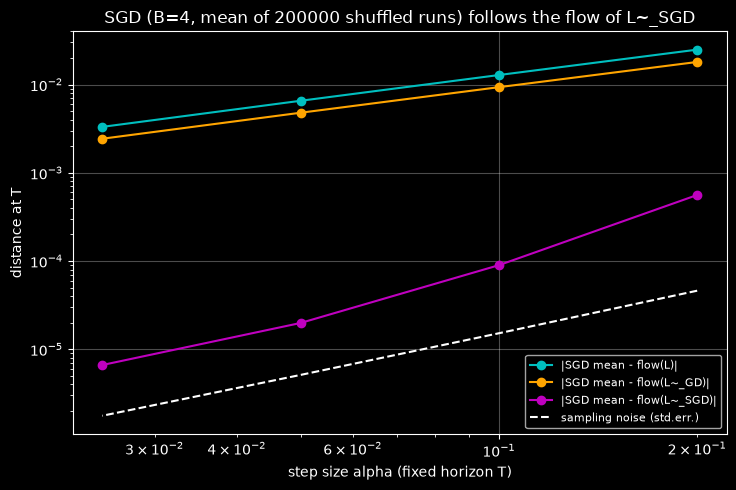

In [28]:
# ============================== 12. PART 5C - SGD (MEAN OVER SHUFFLES) vs THREE CONTINUOUS-TIME FLOWS (2-parameter toy) ==============================
# Fixed partition into B batches; the ORDER of the batches is reshuffled every epoch. We simulate R independent shuffled runs in parallel and
# compare their MEAN iterate (after each epoch, flow time = epoch * B * alpha) with: flow(L), flow(L~_GD), flow(L~_SGD).
# Prediction: the mean SGD path follows flow(L~_SGD), which contains the extra minibatch-variance penalty; flow(L~_GD) is NOT enough.
R_RUNS, T5C = 200_000, 4.0
alphas_5c = [0.2, 0.1, 0.05, 0.025]
def toy_batch_grad(phi_b, xb, yb):                     # phi_b: (R,2); xb, yb: (R, batch)  -> per-run gradient of the batch-mean loss
    with torch.enable_grad():
        p = phi_b.detach().requires_grad_(True)
        g, = torch.autograd.grad(((toy_f(p, xb) - yb) ** 2).mean(1).sum(), p)
    return g.detach()

def sgd_mean_path(alpha, T, R, seed=0):
    gen = torch.Generator(device="cpu"); gen.manual_seed(seed)
    E = int(round(T / (TOY_B * alpha))); phi = TOY.phi0.repeat(R, 1)
    for _ in range(E):
        order = torch.argsort(torch.rand(R, TOY_B, generator=gen, dtype=F64), dim=1)
        for j in range(TOY_B):
            bi = TOY_BATCHES[order[:, j]]                                      # (R, batch)
            phi = phi - alpha * toy_batch_grad(phi, TOY_X[bi], TOY_Y[bi])
    return phi.mean(0), (phi.std(0) / R ** 0.5).norm().item(), E

t2 = torch.tensor([0.0, T5C], dtype=F64)
flowL_c = solve(vf_flow(TOY), TOY.phi0, t2)[-1]
rows = []
for a in alphas_5c:
    m, se, E = sgd_mean_path(a, T5C, R_RUNS)
    fG = solve(vf_mod_gd(TOY, a), TOY.phi0, t2)[-1]; fS = solve(vf_mod_sgd(TOY, a, TOY_BATCHES), TOY.phi0, t2)[-1]
    rows.append((a, E, (m - flowL_c).norm().item(), (m - fG).norm().item(), (m - fS).norm().item(), se))
df5c = pd.DataFrame(rows, columns=["alpha", "epochs", "|SGD mean - flow(L)|", "|SGD mean - flow(L~_GD)|", "|SGD mean - flow(L~_SGD)|", "std.err. of mean"])
print(df5c.to_string(index=False, float_format=lambda v: f"{v:.3e}"))
for col in df5c.columns[2:5]:
    ok = (df5c[col] > 3 * df5c["std.err. of mean"]).to_numpy()
    if ok.sum() >= 2: print(f"slope in alpha for {col}: {loglog_slope(df5c['alpha'][ok], df5c[col][ok]):.2f}  (using {ok.sum()} points above 3 std.err.)")
    else: print(f"{col}: at most one point above the sampling noise floor - slope not estimated")
fig, ax = plt.subplots(figsize=(7.5, 5))
for col, c in zip(df5c.columns[2:5], ("c", "orange", "m")): ax.loglog(df5c["alpha"], df5c[col], "o-", color=c, label=col)
ax.loglog(df5c["alpha"], df5c["std.err. of mean"], "w--", label="sampling noise (std.err.)")
ax.set_xlabel("step size alpha (fixed horizon T)"); ax.set_ylabel("distance at T"); ax.grid(True, alpha=.3); ax.legend(fontsize=8)
ax.set_title(f"SGD (B={TOY_B}, mean of {R_RUNS} shuffled runs) follows the flow of L~_SGD"); fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "part5c_sgd_toy.png"), dpi=150); plt.show()


## 13. Part 5B — the same test on the leak network (smooth tanh, full-batch GD)

leak-net: 102324 parameters, sharpness at init 0.5943, alpha0=4.207e-01, horizon T=1.683e+01
    alpha  n_steps  |GD - flow(L)|  |GD - flow(L~_GD)|  rel. to movement
4.207e-01       40       4.907e-04           2.444e-05         4.407e-03
2.103e-01       80       2.438e-04           6.151e-06         2.190e-03
1.052e-01      160       1.216e-04           1.549e-06         1.092e-03
5.258e-02      320       6.069e-05           3.918e-07         5.450e-04
2.629e-02      640       3.032e-05           1.013e-07         2.723e-04 
(total parameter movement of the flow over T: 1.113e-01;  8s)
log-log slope (smallest alphas): vs flow(L) = 1.00 (theory 1) | vs flow(L~_GD) = 1.97 (theory >= 2)


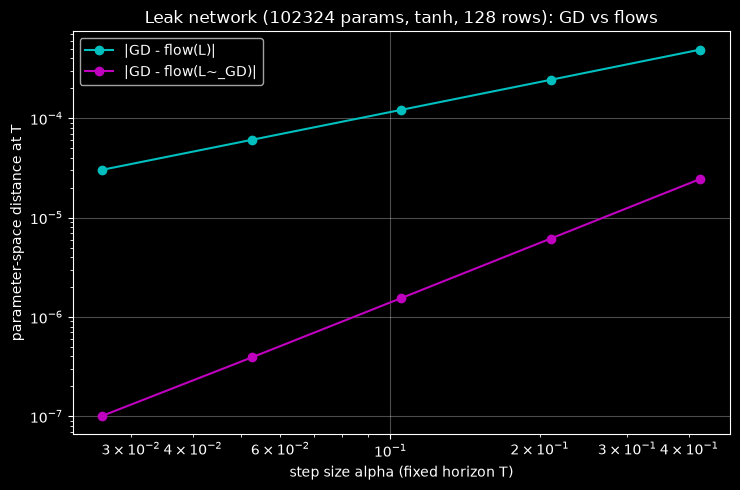

In [29]:
# ============================== 13. PART 5B - SAME TEST ON THE LEAK NETWORK (full-batch GD; smooth tanh network) ==============================
# Tiny subset of training rows, one tanh hidden layer, float64, loss = Phase 1 leak loss. (SGD is verified on the toy only: with ~1e5 parameters the mean over
# shuffles would need far more runs than is affordable to rise above the sampling noise.)
dev5 = device; sizes5 = [DATA["d_in"], CFG["p5_leak_width"], 2 * DATA["d_y"]]
gen5 = torch.Generator(device="cpu"); gen5.manual_seed(SEED + 5)
idx5 = torch.randperm(len(POOL_X), generator=gen5)[:CFG["p5_leak_rows"]].to(device)
X5, Y5 = POOL_X[idx5].to(F64).to(dev5), POOL_Y[idx5].to(F64).to(dev5)

def forward_flat(phi, x):
    h, pos = x, 0
    for i in range(len(sizes5) - 1):
        fi, fo = sizes5[i], sizes5[i + 1]
        W = phi[pos:pos + fo * fi].view(fo, fi); pos += fo * fi
        b = phi[pos:pos + fo]; pos += fo
        h = F.linear(h, W, b)
        if i < len(sizes5) - 2: h = torch.tanh(h)
    return h

def loss5(phi, idx=None):
    x, y = (X5, Y5) if idx is None else (X5[idx], Y5[idx])
    return leak_loss_from_output(forward_flat(phi, x), y)

b5 = fit_constant_baseline(Y5); pr5 = b5["prior"].clamp(1e-4, 0.5)
torch.manual_seed(SEED + 6)
parts = []
for i in range(len(sizes5) - 1):
    parts += [torch.randn(sizes5[i + 1], sizes5[i], dtype=F64, device=dev5).flatten() / math.sqrt(sizes5[i]), torch.zeros(sizes5[i + 1], dtype=F64, device=dev5)]
phi5 = torch.cat(parts)
D5 = DATA["d_y"]; phi5[-2 * D5:-D5] = torch.log(pr5 / (1 - pr5)); phi5[-D5:] = b5["mu_pos"].item()     # start near the constant predictor
LEAK = Problem(loss5, len(X5), phi5, "leak-net")

lam5 = sharpness(LEAK, LEAK.phi0, iters=60)
a0_5 = 0.25 / lam5; n0_5 = 40; T5B = n0_5 * a0_5
alphas_5b = [a0_5 / 2 ** k for k in range(CFG["p5_n_alpha"])]
print(f"leak-net: {phi5.numel()} parameters, sharpness at init {lam5:.4g}, alpha0={a0_5:.3e}, horizon T={T5B:.3e}")
t2 = torch.tensor([0.0, T5B], dtype=F64, device=dev5)
t0 = time.time(); flowL5 = solve(vf_flow(LEAK), LEAK.phi0, t2, rtol=1e-8, atol=1e-10)[-1]
moved = (flowL5 - LEAK.phi0).norm().item(); rows = []
for a in alphas_5b:
    n = int(round(T5B / a)); phi_gd = run_gd(LEAK, a, n, [n])[n]
    flowM5 = solve(vf_mod_gd(LEAK, a), LEAK.phi0, t2, rtol=1e-8, atol=1e-10)[-1]
    rows.append((a, n, (phi_gd - flowL5).norm().item(), (phi_gd - flowM5).norm().item()))
df5b = pd.DataFrame(rows, columns=["alpha", "n_steps", "|GD - flow(L)|", "|GD - flow(L~_GD)|"])
df5b["rel. to movement"] = df5b["|GD - flow(L)|"] / moved
print(df5b.to_string(index=False, float_format=lambda v: f"{v:.3e}"), f"\n(total parameter movement of the flow over T: {moved:.3e};  {time.time() - t0:.0f}s)")
k0 = max(0, len(alphas_5b) - 3)
if len(alphas_5b) >= 2:
    print(f"log-log slope (smallest alphas): vs flow(L) = {loglog_slope(alphas_5b[k0:], df5b.iloc[k0:, 2]):.2f} (theory 1) | vs flow(L~_GD) = {loglog_slope(alphas_5b[k0:], df5b.iloc[k0:, 3]):.2f} (theory >= 2)")
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.loglog(alphas_5b, df5b.iloc[:, 2], "co-", label="|GD - flow(L)|"); ax.loglog(alphas_5b, df5b.iloc[:, 3], "mo-", label="|GD - flow(L~_GD)|")
ax.set_xlabel("step size alpha (fixed horizon T)"); ax.set_ylabel("parameter-space distance at T"); ax.grid(True, alpha=.3); ax.legend()
ax.set_title(f"Leak network ({phi5.numel()} params, tanh, {len(X5)} rows): GD vs flows"); fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "part5b_gd_leaknet.png"), dpi=150); plt.show()


## 14. Part 5D — why Adam is not part of the §9.2 test

    alpha  n_steps  |GD - flow(L)|  |Adam - flow(L)|
5.000e-02       80       1.787e-03         2.011e-01
2.000e-02      200       7.122e-04         1.945e-01
1.000e-02      400       3.557e-04         1.945e-01
5.000e-03      800       1.777e-04         1.944e-01
2.000e-03     2000       7.106e-05         1.944e-01
GD -> flow(L) as alpha -> 0; Adam does not. A UDL 9.2-style analysis for Adam would need Adam's OWN continuous-time limit and a source that derives its modified loss; none is used here.


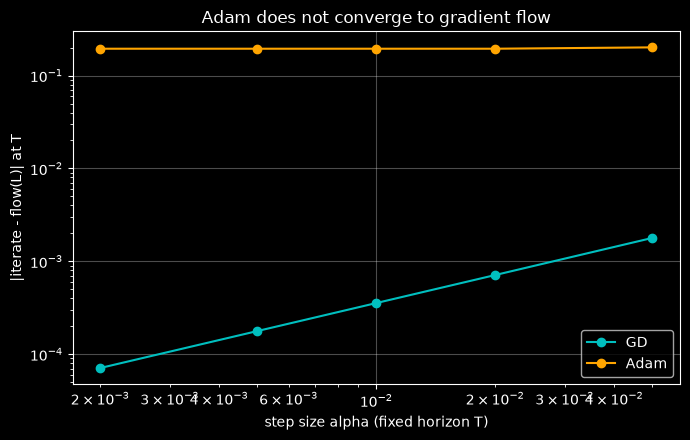

In [30]:
# ============================== 14. PART 5D - WHY ADAM IS NOT PART OF THE UDL 9.2 TEST ==============================
# Adam's update is alpha * m_hat / (sqrt(v_hat) + eps): for small alpha it moves each parameter by ~alpha per step REGARDLESS of the gradient size
# (sign-like), so under the time map t = n*alpha it does NOT approach the gradient flow of L, however small alpha is. GD does. (Full-batch, toy, float64.)
alphas_5d, T5D = [0.05, 0.02, 0.01, 0.005, 0.002], 4.0
t2 = torch.tensor([0.0, T5D], dtype=F64); flowL_d = solve(vf_flow(TOY), TOY.phi0, t2)[-1]
rows = []
for a in alphas_5d:
    n = int(round(T5D / a))
    phi_a = TOY.phi0.clone(); adam = AdamScratch([phi_a], lr=a)
    for _ in range(n): adam.step([grad_at(TOY, phi_a)])
    phi_g = run_gd(TOY, a, n, [n])[n]
    rows.append((a, n, (phi_g - flowL_d).norm().item(), (phi_a - flowL_d).norm().item()))
df5d = pd.DataFrame(rows, columns=["alpha", "n_steps", "|GD - flow(L)|", "|Adam - flow(L)|"])
print(df5d.to_string(index=False, float_format=lambda v: f"{v:.3e}"))
print("GD -> flow(L) as alpha -> 0; Adam does not. A UDL 9.2-style analysis for Adam would need Adam's OWN continuous-time limit and a source that derives its modified loss; none is used here.")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(df5d["alpha"], df5d.iloc[:, 2], "co-", label="GD"); ax.loglog(df5d["alpha"], df5d.iloc[:, 3], "o-", color="orange", label="Adam")
ax.set_xlabel("step size alpha (fixed horizon T)"); ax.set_ylabel("|iterate - flow(L)| at T"); ax.grid(True, alpha=.3); ax.legend(); ax.set_title("Adam does not converge to gradient flow")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "part5d_adam_vs_flow.png"), dpi=150); plt.show()
